In [1]:
# -*- coding: utf-8 -*-
"""
GWTC-3 BBH Population Inference with GMM Selection Function
============================================================
Implements Talbot & Thrane (2022) [arXiv:2012.01317] selection function
estimation via Gaussian Mixture Model with empirical CDF pre-processing,
applied to GWTC-3 binary black hole mergers.

Inference methods
-----------------
Method 1 : Direct importance-sampling reweight of found injections
Method 3 : Guided IS per-event term + GMM-based selection function
"""

'\nGWTC-3 BBH Population Inference with GMM Selection Function\n============================================================\nImplements Talbot & Thrane (2022) [arXiv:2012.01317] selection function\nestimation via Gaussian Mixture Model with empirical CDF pre-processing,\napplied to GWTC-3 binary black hole mergers.\n\nInference methods\n-----------------\nMethod 1 : Direct importance-sampling reweight of found injections\nMethod 3 : Guided IS per-event term + GMM-based selection function\n'

## SECTION 0 – SETUP  (run in Colab)


In [2]:
!pip install healpy dynesty corner
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/popnflow_goog/jaxinterp2d')
!pip install /content/drive/MyDrive/popnflow_goog/jaxinterp2d

import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 128.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.9/102.9 kB 12.2 MB/s eta 0:00:00
Mounted at /content/drive
Processing ./drive/MyDrive/popnflow_goog/jaxinterp2d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for jaxinterp2d: filename=jaxinterp2d-0.0.1-py3-none-any.whl size=4112 sha256=b88cd8d12c689c06a897400026d5e3da6ed21eee03e218fa490073bd661be878
  Stored in directory: /tmp/pip-ephem-wheel-cache-5dsi3yr4/wheels/e2/d5/00/104e6fff379246b0eb56f227618a8416dc26f0cbfa684802b3
Successfully built jaxinterp2d


## SECTION 1 – IMPORTS & CONFIGURATION


In [3]:
import numpy as np
import h5py
from tqdm import tqdm

import jax
import jax.numpy as jnp
import jax.scipy as jsp
from jax import jit, random
from jax.scipy.special import logsumexp, erf, erfinv

import astropy.units as u
import astropy.constants as constants
from astropy.cosmology import Planck15, FlatLambdaCDM

from scipy.stats import gaussian_kde, norm as scipy_norm
from scipy.integrate import cumulative_trapezoid
from scipy.special import logit, expit
from sklearn.mixture import GaussianMixture

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({
    'font.family': 'Times New Roman',
    'text.usetex': False,
    'mathtext.fontset': 'cm',
    'figure.figsize': (12, 8),
})
import seaborn as sns
sns.set_context('talk')
sns.set_style('ticks')

from jaxinterp2d import interp2d
from functools import partial

jax.config.update("jax_enable_x64", True)
jax.config.update('jax_default_matmul_precision', 'highest')
print(f"JAX version: {jax.__version__},  devices: {jax.devices()}")

JAX version: 0.7.2,  devices: [CudaDevice(id=0)]


## SECTION 2 – COSMOLOGY


In [4]:
H0Planck  = Planck15.H0.value
Om0Planck = Planck15.Om0
c_kms     = constants.c.to('km/s').value

zMax    = 2.0
zgrid   = jnp.expm1(np.linspace(np.log(1), np.log(zMax + 1), 10_000))
Om0grid = jnp.linspace(0, 1, 1_000)

print("Building comoving distance table …")
rs_list = []
for Om0 in tqdm(Om0grid):
    cosmo = FlatLambdaCDM(H0=H0Planck, Om0=float(Om0))
    rs_list.append(cosmo.comoving_distance(zgrid).to(u.Mpc).value)
rs = jnp.asarray(rs_list).reshape(len(Om0grid), len(zgrid))


@jit
def E(z, Om0=Om0Planck):
    return jnp.sqrt(Om0 * (1 + z)**3 + (1.0 - Om0))

@jit
def r_of_z(z, H0, Om0=Om0Planck):
    return interp2d(Om0, z, Om0grid, zgrid, rs) * (H0Planck / H0)

@jit
def dL_of_z(z, H0, Om0=Om0Planck):
    return (1 + z) * r_of_z(z, H0, Om0)

@jit
def z_of_dL(dL, H0, Om0=Om0Planck):
    return jnp.interp(dL, dL_of_z(zgrid, H0, Om0), zgrid)

@jit
def dV_of_z(z, H0, Om0=Om0Planck):
    return c_kms * r_of_z(z, H0, Om0)**2 / (H0 * E(z, Om0))

@jit
def ddL_of_z(z, dL, H0, Om0=Om0Planck):
    return dL / (1 + z) + c_kms * (1 + z) / (H0 * E(z, Om0))

Building comoving distance table …


100%|██████████| 1000/1000 [00:21<00:00, 45.73it/s]


## SECTION 3 – LOAD EVENT POSTERIOR SAMPLES


In [5]:
# DATA_DIR = '/content/drive/MyDrive/potato_man'
DATA_DIR = '/content/drive/MyDrive/popnflow_goog'

# dL_raw    = np.loadtxt(f'{DATA_DIR}/mdc_dL_69rand.txt')
# m1det_raw = np.loadtxt(f'{DATA_DIR}/mdc_m1det_69rand.txt')
# m2det_raw = np.loadtxt(f'{DATA_DIR}/mdc_m2det_69rand.txt')

dL_raw    = np.load(f'{DATA_DIR}/cat019_dL.npy')
m1det_raw = np.load(f'{DATA_DIR}/cat019_m1det.npy')
m2det_raw = np.load(f'{DATA_DIR}/cat019_m2det.npy')


Nobs  = 69
nsamp = 3343

dL    = jnp.asarray(dL_raw)
m1det = jnp.asarray(m1det_raw)
m2det = jnp.asarray(m2det_raw)

dL_    = dL.reshape(Nobs, nsamp)
m1det_ = m1det.reshape(Nobs, nsamp)
m2det_ = m2det.reshape(Nobs, nsamp)

# Source-frame masses (PE prior assumed ∝ dL²)
z_ev  = z_of_dL(dL, H0Planck, Om0Planck)
m1_ev = m1det / (1 + z_ev)
m2_ev = m2det / (1 + z_ev)

print(f"Loaded {Nobs} events, {nsamp} samples each.")

Loaded 69 events, 3343 samples each.


## SECTION 4 – LOAD INJECTION DATA


In [6]:
INJECTION_FILE = '/content/drive/MyDrive/popnflow_goog/endo3_bbhpop-LIGO-T2100113-v12.hdf5'

with h5py.File(INJECTION_FILE, 'r') as f:
    Tobs  = f.attrs['analysis_time_s'] / (365.25 * 24 * 3600)
    Ndraw = int(f.attrs['total_generated'])   # NEVER overwrite this

    m1detsels_all    = f['injections/mass1'][:]
    m2detsels_all    = f['injections/mass2'][:]
    dLsels_all       = f['injections/distance'][:]
    p_draw_all       = f['injections/sampling_pdf'][:]
    ifar_gstlal      = f['injections/ifar_gstlal'][:]
    ifar_pycbc_bbh   = f['injections/ifar_pycbc_bbh'][:]
    ifar_pycbc_broad = f['injections/ifar_pycbc_hyperbank'][:]

sels    = (ifar_gstlal > 1) | (ifar_pycbc_bbh > 1) | (ifar_pycbc_broad > 1)
N_found = int(sels.sum())

m1detsels = jnp.asarray(m1detsels_all[sels])
m2detsels = jnp.asarray(m2detsels_all[sels])
dLsels    = jnp.asarray(dLsels_all[sels])
p_draw    = jnp.asarray(p_draw_all[sels])

zsels  = z_of_dL(dLsels, H0Planck, Om0Planck)
m1sels = m1detsels / (1 + zsels)
m2sels = m2detsels / (1 + zsels)

print(f"Ndraw (total generated): {Ndraw:,}")
print(f"N_found (IFAR > 1 yr):  {N_found:,}")
print(f"Observation time:        {Tobs:.2f} yr")

Ndraw (total generated): 73,957,576
N_found (IFAR > 1 yr):  76,202
Observation time:        0.91 yr


## SECTION 5 – POPULATION MODEL


In [7]:
mass       = jnp.linspace(1, 150, 2_000)
mass_ratio = jnp.linspace(1e-5, 1, 2_000)


def Sfilter_low(m, m_min, dm_min):
    def f(mm, dM): return jnp.exp(dM / mm + dM / (mm - dM))
    S = 1.0 / (f(m - m_min, dm_min) + 1.0)
    S = jnp.where(m < m_min + dm_min, S, 1.0)
    S = jnp.where(m > m_min, S, 0.0)
    return S


def Sfilter_high(m, m_max, dm_max):
    def f(mm, dM): return jnp.exp(dM / mm + dM / (mm - dM))
    S = 1.0 / (f(m - m_max, -dm_max) + 1.0)
    S = jnp.where(m > m_max - dm_max, S, 1.0)
    S = jnp.where(m < m_max, S, 0.0)
    return S


@jit
def logpm1_powerlaw(m1, m_min, m_max, alpha, dm_min, dm_max):
    pm1 = Sfilter_low(mass, m_min, dm_min) * mass**(-alpha) * Sfilter_high(mass, m_max, dm_max)
    pm1 = pm1 / jnp.trapezoid(pm1, mass)
    return jnp.log(jnp.interp(m1, mass, pm1))


@jit
def logpm1_peak(m1, mu, sigma):
    pm1 = jnp.exp(-(mass - mu)**2 / (2 * sigma**2))
    pm1 = pm1 / jnp.trapezoid(pm1, mass)
    return jnp.log(jnp.interp(m1, mass, pm1))


@jit
def logpm1_pl_peak(m1, m_min, m_max, alpha, dm_min, dm_max, mu, sigma, f1):
    p1 = jnp.exp(logpm1_powerlaw(m1, m_min, m_max, alpha, dm_min, dm_max))
    p2 = jnp.exp(logpm1_peak(m1, mu, sigma))
    return jnp.log((1 - f1) * p1 + f1 * p2)


@jit
def logfq(m1, m2, beta):
    q  = m2 / m1
    pq = mass_ratio**beta
    pq = pq / jnp.trapezoid(pq, mass_ratio)
    return jnp.log(jnp.interp(q, mass_ratio, pq))


@jit
def dV_of_z_normed(z, Om0, gamma):
    dV  = dV_of_z(zgrid, H0Planck, Om0) * (1 + zgrid)**(gamma - 1)
    pdf = dV / jnp.trapezoid(dV, zgrid)
    return jnp.interp(z, zgrid, pdf)


@jit
def log_p_pop_pl_pl(m1, m2, z, gamma,
                    m_min, m_max, alpha, dm_min, dm_max,
                    beta, mu, sigma, f1):
    """Full population log-probability in SOURCE FRAME."""
    log_pm1  = logpm1_pl_peak(m1, m_min, m_max, alpha, dm_min, dm_max, mu, sigma, f1)
    log_pm2  = logpm1_pl_peak(m2, m_min, m_max, alpha, dm_min, dm_max, mu, sigma, f1)
    log_pq   = logfq(m1, m2, beta)
    log_dvdz = jnp.log(dV_of_z_normed(z, Om0Planck, gamma))
    log_p_sz = jnp.log(0.25)   # uniform spin tilts marginalised
    log_p    = log_p_sz + log_pm1 + log_pm2 + log_pq + log_dvdz
    return jnp.where(m2 < m1, log_p, -jnp.inf)


@jax.jit
def powerlaw_ln_normalization_jax(alpha, minimum, maximum):
    return jnp.log((1.0 + alpha) / (maximum**(1.0 + alpha) - minimum**(1.0 + alpha)))

@jax.jit
def powerlaw_ln_pdf_jax(value, alpha, minimum, maximum):
    log_prob = alpha * jnp.log(value) + powerlaw_ln_normalization_jax(alpha, minimum, maximum)
    return jnp.where((value >= minimum) & (value <= maximum), log_prob, -jnp.inf)

@jax.jit
def log_p_injection_prior(m1, m2, z, dL_val):
    """endo3 injection prior in source frame (m1, m2, z)."""
    log_p_m1 = powerlaw_ln_pdf_jax(m1, alpha=-2.35, minimum=2.0, maximum=100.0)
    log_p_q  = powerlaw_ln_pdf_jax(m2 / m1, alpha=1.0, minimum=2.0 / m1, maximum=1.0)
    log_dvdz = jnp.log(dV_of_z_normed(z, Om0Planck, gamma=1.0))
    return log_p_m1 + log_p_q + log_dvdz - jnp.log(m1)

In [8]:
@jit
def logpm1m2_plpeak_massratio(
    m1, m2,
    m_min_1, m_max_1,
    alpha_1,
    beta, mu, sigma,
    f
):
    q = m2/m1
    alpha_1 = -alpha_1
    # --- p(m1): Power-law component ---
    norm_pl = (m_max_1**(1. + alpha_1) - m_min_1**(1. + alpha_1))
    p_m1_pl = (1. + alpha_1) * m1**alpha_1 / norm_pl

    # Mask out-of-range m1
    p_m1_pl = jnp.where(m1 > m_max_1, 0.0, p_m1_pl)
    p_m1_pl = jnp.where(m1 < m_min_1, 0.0, p_m1_pl)

    # --- p(m1): Peak component ---
    p_m1_peak = jnp.exp(-0.5 * (m1 - mu)**2 / sigma**2) / jnp.sqrt(2. * jnp.pi * sigma**2)

    # Mixture
    p_m1 = f * p_m1_peak + (1. - f) * p_m1_pl

    # --- p(q | m1): mass-ratio power law ---
    q_min = m_min_1/m1
    q_min = jnp.clip(q_min, a_min=0.0, a_max=1-1e-5)
    denom = 1 - q_min**(1. + beta)
    p_q = (1. + beta) * q**beta / denom

    # Enforce m2 >= m_min_1
    p_q = jnp.where(q*m1 < m_min_1, 0.0, p_q)

    # --- log joint ---
    return jnp.log(p_m1) + jnp.log(p_q) - jnp.log(m1)

from jax.scipy.stats import norm

@jit
def logpm1m2_plpeak_massratio(m1, m2, m_min_1, m_max_1, alpha_1, beta, mu, sigma, f):
    q = m2/m1
    alpha_1 = -alpha_1

    # --- p(m1): Power-law component ---
    norm_pl = (m_max_1**(1. + alpha_1) - m_min_1**(1. + alpha_1))
    p_m1_pl = (1. + alpha_1) * m1**alpha_1 / norm_pl

    # --- p(m1): Peak component (FIXED) ---
    # 1. Evaluate the raw Gaussian
    p_m1_peak = jnp.exp(-0.5 * (m1 - mu)**2 / sigma**2) / jnp.sqrt(2. * jnp.pi * sigma**2)

    # 2. Re-normalize the Gaussian so it integrates to 1 exactly between the bounds
    cdf_max = norm.cdf(m_max_1, loc=mu, scale=sigma)
    cdf_min = norm.cdf(m_min_1, loc=mu, scale=sigma)
    p_m1_peak = p_m1_peak / (cdf_max - cdf_min)

    # --- Masking BOTH components (FIXED) ---
    # Mask out-of-range m1 for BOTH power-law and peak to prevent probability leakage
    in_bounds = (m1 >= m_min_1) & (m1 <= m_max_1)
    p_m1_pl = jnp.where(in_bounds, p_m1_pl, 0.0)
    p_m1_peak = jnp.where(in_bounds, p_m1_peak, 0.0)

    # Mixture
    p_m1 = f * p_m1_peak + (1. - f) * p_m1_pl

    # --- p(q | m1): mass-ratio power law ---
    q_min = m_min_1/m1
    denom = 1 - q_min**(1. + beta)
    p_q = (1. + beta) * q**beta / denom

    # Enforce m2 >= m_min_1
    p_q = jnp.where(q*m1 < m_min_1, 0.0, p_q)

    # --- log joint ---
    # (Keeping the vital - jnp.log(m1) Jacobian fix here!)
    return jnp.log(p_m1) + jnp.log(p_q) - jnp.log(m1)


@jit
def log_p_pop_lvk(m1,m2,z,gamma, m_min_1,m_max_1,alpha_1,beta,mu,sigma,f):

    log_pm1m2 = logpm1m2_plpeak_massratio(m1, m2, m_min_1, m_max_1, alpha_1, beta, mu, sigma, f)
    log_pz = jnp.log(dV_of_z_normed(z,Om0Planck,gamma))

    log_p = log_pm1m2 + log_pz
    log_p = jnp.where(m2<m1, log_p, -jnp.inf)
    return log_p

## SECTION 6 – SELECTION FUNCTION GMM


In [9]:
# ---- 6.1  Reflecting KDE ----
class ReflectingKDE(gaussian_kde):
    def __init__(self, dataset, bw_method=None, weights=None,
                 minimum=-np.inf, maximum=np.inf):
        super().__init__(dataset=dataset, bw_method=bw_method, weights=weights)
        self.minimum = minimum
        self.maximum = maximum
        self.range   = self.maximum - self.minimum

    def __call__(self, points):
        prob     = self.evaluate(points)
        fraction = (points - self.minimum) / self.range
        if self.minimum > -np.inf:
            prob += self.evaluate(self.minimum - fraction * self.range)
            prob *= (points >= self.minimum)
        if self.maximum < np.inf:
            prob += self.evaluate(self.maximum + (1.0 - fraction) * self.range)
            prob *= (points <= self.maximum)
        return prob


# ---- 6.2  Resample found injections (de-bias p_draw) ----
lq_sels_np = logit(np.asarray(m2detsels) / np.asarray(m1detsels))
X_raw      = np.column_stack([np.asarray(m1detsels), lq_sels_np, np.asarray(dLsels)])

m1_resam = X_raw[:, 0]
lq_resam = X_raw[:, 1]
dL_resam = X_raw[:, 2]

# Physical validity mask
q_resam  = expit(lq_resam)
m2_resam = m1_resam * q_resam
z_resam  = np.asarray(z_of_dL(jnp.asarray(dL_resam), H0Planck, Om0Planck))
phys_mask = (
    (m1_resam >= 2.0) & (m1_resam <= 100.0) &
    (m2_resam >= 2.0) & (m2_resam <= m1_resam) &
    (q_resam  >= 2.0 / m1_resam) &
    (z_resam  >= 0.0) & (z_resam  <= 1.9) &
    (dL_resam >= 50.0)
)
m1_resam = m1_resam[phys_mask]
lq_resam = lq_resam[phys_mask]
dL_resam = dL_resam[phys_mask]
print(f"Found injections after mask: {phys_mask.sum():,} / {len(phys_mask):,} "
      f"({phys_mask.mean()*100:.1f}% valid)")

# ---- 6.3  Empirical CDF grids ----
GRID_N   = 10_000
FIT_KEYS = ["mass_1", "lq", "dL"]

data_dict = {"mass_1": m1_resam, "lq": lq_resam, "dL": dL_resam}
ranges    = {
    "mass_1": (2.0, 150.0),
    "lq":     (float(np.percentile(lq_resam, 0.05)),
               float(np.percentile(lq_resam, 99.95))),
    "dL":     (0.0, float(np.max(dLsels)) * 1.05),
}

lnpdf_grids = {}
cdf_grids   = {}
grid_meta   = {}

for key in FIT_KEYS:
    arr        = data_dict[key]
    min_, max_ = ranges[key]
    domain     = np.linspace(min_, max_, GRID_N)

    if key == "mass_1":
        kde  = ReflectingKDE(arr, minimum=min_, maximum=max_, weights=arr**0.5)
        epdf = kde(domain) * domain**-0.5
        epdf /= np.trapz(epdf, domain)
    else:
        kde  = ReflectingKDE(arr, minimum=min_, maximum=max_)
        epdf = kde(domain)

    epdf = np.clip(epdf, 1e-300, None)
    ecdf = cumulative_trapezoid(epdf, domain, initial=0)
    ecdf = np.clip(ecdf / ecdf[-1], 1e-12, 1.0 - 1e-12)

    lnpdf_grids[key] = jnp.asarray(np.log(epdf))
    cdf_grids[key]   = jnp.asarray(ecdf)
    grid_meta[key]   = {"min": min_, "delta": (max_ - min_) / (GRID_N - 1)}

print("Empirical CDF grids built for:", FIT_KEYS)


# ---- 6.4  JAX fast interpolation ----
@jax.jit
def _fast_interp(point, x_min, delta_x, y_grid):
    idx  = jnp.clip(
        jnp.floor((point - x_min) / delta_x).astype(jnp.int32),
        0, y_grid.shape[0] - 2,
    )
    frac = jnp.clip((point - (x_min + idx * delta_x)) / delta_x, 0.0, 1.0)
    return (1.0 - frac) * y_grid[idx] + frac * y_grid[idx + 1]


# ---- 6.5  CDF ↔ probit transforms ----
def apply_empirical_transform_np(m1_arr, lq_arr, dL_arr):
    """Physical (m1, lq, dL) → whitened N(0,I)."""
    out = np.zeros((len(m1_arr), 3))
    for ii, (key, arr) in enumerate(zip(FIT_KEYS, [m1_arr, lq_arr, dL_arr])):
        meta   = grid_meta[key]
        domain = np.linspace(meta["min"], meta["min"] + meta["delta"] * (GRID_N - 1), GRID_N)
        u = np.interp(arr, domain, np.asarray(cdf_grids[key]))
        u = np.clip(u, 1e-12, 1.0 - 1e-12)
        out[:, ii] = scipy_norm.ppf(u)
    return out


def unscale_from_white(X_white):
    """Whitened N(0,I) → physical (m1, lq, dL)."""
    out = np.zeros_like(X_white)
    for ii, key in enumerate(FIT_KEYS):
        meta   = grid_meta[key]
        domain = np.linspace(meta["min"], meta["min"] + meta["delta"] * (GRID_N - 1), GRID_N)
        u = scipy_norm.cdf(X_white[:, ii])
        u = np.clip(u, 1e-12, 1.0 - 1e-12)
        out[:, ii] = np.interp(u, np.asarray(cdf_grids[key]), domain)
    return out


X_white = apply_empirical_transform_np(m1_resam, lq_resam, dL_resam)
print(f"Whitened data:  mean={X_white.mean(axis=0).round(3)},  "
      f"std={X_white.std(axis=0).round(3)}")


# ---- 6.6  Select number of GMM components ----
n_train  = int(0.8 * len(X_white))
idx_perm = np.random.permutation(len(X_white))
X_train  = X_white[idx_perm[:n_train]]
X_test   = X_white[idx_perm[n_train:]]

# print("Scanning GMM components …")
# for n_comp in range(1, 21):
#     g = GaussianMixture(n_components=n_comp, covariance_type='full',
#                         random_state=0).fit(X_train)
#     print(f"  K={n_comp:2d}  test score={g.score(X_test):.4f}")

N_COMPONENTS_SEL = 10
print(f"Using K={N_COMPONENTS_SEL}")


# ---- 6.7  Fit selection GMM ----
gmm_sel = GaussianMixture(n_components=N_COMPONENTS_SEL, covariance_type='full',
                           random_state=0, n_init=3).fit(X_white)

wts_sel     = jnp.asarray(gmm_sel.weights_,    dtype=jnp.float64)
mus_sel     = jnp.asarray(gmm_sel.means_,      dtype=jnp.float64)
prec_sel    = jnp.asarray(gmm_sel.precisions_, dtype=jnp.float64)
logdets_sel = jnp.asarray(
    -2.0 * np.sum(np.log(np.diagonal(gmm_sel.precisions_cholesky_,
                                     axis1=-2, axis2=-1)), axis=-1),
    dtype=jnp.float64,
)
print(f"Selection GMM fitted (K={N_COMPONENTS_SEL}, score={gmm_sel.score(X_white):.4f})")


# ---- 6.8  ln p̃_found in physical (m1, lq, dL) space ----
@jax.jit
def unit_normal_ln_pdf_jax(x):
    return -0.5 * jnp.log(2.0 * jnp.pi) - 0.5 * x**2

@jax.jit
def ln_pdf_empirical_jax(m1, lq, dL_val, wts, mus, precisions, logdets):
    """
    log p̃_found(m1, lq, dL): GMM density mapped back to physical space
    via the chain-rule Jacobian of the CDF→probit transform.
    (Eq. 26/28 of Talbot & Thrane 2022)
    """
    def _cdf(val, key):
        m = grid_meta[key]
        return _fast_interp(val, m["min"], m["delta"], cdf_grids[key])

    def _probit(u):
        return jnp.sqrt(2.0) * erfinv(2.0 * jnp.clip(u, 1e-12, 1.0 - 1e-12) - 1.0)

    th_m1 = _probit(_cdf(m1,     "mass_1"))
    th_lq = _probit(_cdf(lq,     "lq"))
    th_dL = _probit(_cdf(dL_val, "dL"))
    theta_prime = jnp.stack([th_m1, th_lq, th_dL], axis=-1)

    K, D     = mus.shape
    diffs    = theta_prime[:, None, :] - mus[None, :, :]
    quad     = jnp.einsum("nkd,kdj,nkj->nk", diffs, precisions, diffs)
    log_comp = -0.5 * (D * jnp.log(2.0 * jnp.pi) + logdets[None, :] + quad)
    logw     = jnp.log(jnp.clip(wts, 1e-12, 1.0))[None, :]
    log_D    = jsp.special.logsumexp(logw + log_comp, axis=-1)

    def _ln_epdf(val, key):
        m = grid_meta[key]
        return _fast_interp(val, m["min"], m["delta"], lnpdf_grids[key])

    log_jac = (
          _ln_epdf(m1,     "mass_1") - unit_normal_ln_pdf_jax(th_m1)
        + _ln_epdf(lq,     "lq")     - unit_normal_ln_pdf_jax(th_lq)
        + _ln_epdf(dL_val, "dL")     - unit_normal_ln_pdf_jax(th_dL)
    )
    return log_D + log_jac


Found injections after mask: 63,201 / 76,202 (82.9% valid)


/tmp/ipykernel_4600/1805400519.py:71: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  epdf /= np.trapz(epdf, domain)


Empirical CDF grids built for: ['mass_1', 'lq', 'dL']
Whitened data:  mean=[0.006 0.001 0.012],  std=[0.976 1.013 0.967]
Using K=10
Selection GMM fitted (K=10, score=-3.6819)


In [10]:
# ---- 6.9  Build GMM-based IS pool (drawn once, used every likelihood call) ----
#
# Why GMM samples instead of uniform pool:
#   Uniform (m1, q, z) pool: IS weight variance is very high for peaked
#   population models → Neff << 4*Nobs at many valid prior points.
#   GMM samples drawn from p_found: almost all are detectable, so the
#   IS weight w_i = p_pop(θ_i)/p_inj(θ_i) has low variance → high Neff.
#
# IS identity: P_det(Λ) = E_{p_found}[p_pop(θ|Λ) / p_inj(θ)]
# The proposal density p_found cancels analytically — only p_pop/p_inj needed.

N_GMM = 80000   # draw once offline; make as large as memory allows

gmm_samples_raw = gmm_sel.sample(N_GMM)[0]          # whitened (N_GMM, 3)
gmm_phys        = unscale_from_white(gmm_samples_raw)  # physical (m1, lq, dL)

# The GMM was fitted in DETECTOR frame (m1_det, logit(q), dL).
# After unscaling, gmm_phys[:,0] is m1_DET and gmm_phys[:,2] is dL.
# q = m2/m1 is frame-invariant (both masses scale equally with 1+z).
# We must convert to SOURCE frame before passing to log_p_pop and log_p_inj,
# which both expect source-frame masses.
gmm_m1det_all = jnp.asarray(gmm_phys[:, 0])          # detector-frame m1
gmm_q_all     = jnp.asarray(expit(gmm_phys[:, 1]))    # q = m2/m1  (frame-invariant)
gmm_m2det_all = gmm_m1det_all * gmm_q_all             # detector-frame m2
gmm_dL_all    = jnp.asarray(gmm_phys[:, 2])           # luminosity distance [Mpc]
gmm_z_all     = z_of_dL(gmm_dL_all, H0Planck, Om0Planck)

# Convert detector → source frame:  m_src = m_det / (1 + z)
gmm_m1_all = gmm_m1det_all / (1.0 + gmm_z_all)        # SOURCE-frame m1
gmm_m2_all = gmm_m2det_all / (1.0 + gmm_z_all)        # SOURCE-frame m2

# Injection prior in source-frame (m1_src, m2_src, z) — now correctly in source frame
gmm_log_p_inj_all = log_p_injection_prior(gmm_m1_all, gmm_m2_all, gmm_z_all, gmm_dL_all)

# Validity mask: bounds apply to SOURCE-frame masses
valid = (
    jnp.isfinite(gmm_log_p_inj_all) &
    (gmm_m1_all >= 2.0)  & (gmm_m1_all <= 100.0) &
    (gmm_m2_all >= 2.0)  & (gmm_m2_all <= 100.0) &
    (gmm_m2_all <= gmm_m1_all) &
    (gmm_z_all  >= 0.0)  & (gmm_z_all  <= 1.9)   &
    (gmm_dL_all >= 50.0)
)

# Store SOURCE-frame masses — these are what log_p_pop_pl_pl expects
gmm_m1        = gmm_m1_all[valid]
gmm_m2        = gmm_m2_all[valid]
gmm_z         = gmm_z_all[valid]
gmm_log_p_inj = gmm_log_p_inj_all[valid]
N_GMM_valid   = int(valid.sum())

print(f"GMM pool: {N_GMM_valid:,} / {N_GMM:,} valid ({100*N_GMM_valid/N_GMM:.1f}%)")
print(f"  Source-frame m1: [{float(gmm_m1.min()):.1f}, {float(gmm_m1.max()):.1f}] M☉"
      f"  (expect [2, 100])")

# Sanity check: IS weights should be finite and bounded
_test_coord = jnp.array([3., 5., 80., 1.5, 2., 3., 1., 35., 5., 0.2])
_lw = log_p_pop_pl_pl(gmm_m1, gmm_m2, gmm_z, *_test_coord) - gmm_log_p_inj
print(f"IS weight sanity (test coord):  "
      f"finite={float(jnp.isfinite(_lw).mean()):.3f},  "
      f"max={float(jnp.nanmax(_lw)):.2f},  min={float(jnp.nanmin(_lw)):.2f}")

GMM pool: 79,364 / 80,000 valid (99.2%)
  Source-frame m1: [2.0, 96.0] M☉  (expect [2, 100])
IS weight sanity (test coord):  finite=1.000,  max=1.94,  min=-128.57


In [11]:
oldm1 = gmm_m1
oldm2 = gmm_m2
oldz  = gmm_z
olddL = gmm_dL_all

In [12]:
N_GMM_valid_old = N_GMM_valid
gmm_log_p_inj_old = gmm_log_p_inj

## SECTION 7 – PER-EVENT GMMs  (guided importance sampling)


In [13]:
# ---- 7.1  GMM density helpers ----
@jax.jit
def exact_log_gmm(x_ND, w_K, mu_KD, Prec_KDD, logdetS_K):
    D        = mu_KD.shape[-1]
    diffs    = x_ND[:, None, :] - mu_KD[None, :, :]
    quad     = jnp.einsum('nkd,kdj,nkj->nk', diffs, Prec_KDD, diffs)
    log_comp = -0.5 * (D * jnp.log(2 * jnp.pi) + logdetS_K[None, :] + quad)
    logw     = jnp.log(jnp.clip(w_K, 1e-300, 1.0))[None, :]
    return jsp.special.logsumexp(logw + log_comp, axis=-1)


@jax.jit
def log_gmm_symmetrized(x_sorted, w_K, mu_KD, Prec_KDD, logdetS_K):
    """p_ord(x) = p(x) + p(swap(x)) — accounts for m1/m2 label symmetry."""
    x_swap      = x_sorted.at[:, :2].set(x_sorted[:, [1, 0]])
    log_px      = exact_log_gmm(x_sorted, w_K, mu_KD, Prec_KDD, logdetS_K)
    log_px_swap = exact_log_gmm(x_swap,   w_K, mu_KD, Prec_KDD, logdetS_K)
    return jsp.special.logsumexp(jnp.stack([log_px, log_px_swap]), axis=0)


def batched_log_gmm_sym(x, w_K, mu_KD, Prec_KDD, logdetS_K, batch_size=5_000):
    """
    Memory-safe batched evaluation of log_gmm_symmetrized.
    Tune batch_size down if OOM, up for speed.
    """
    N      = x.shape[0]
    chunks = []
    for start in range(0, N, batch_size):
        chunks.append(
            jax.device_get(
                log_gmm_symmetrized(x[start:start + batch_size],
                                    w_K, mu_KD, Prec_KDD, logdetS_K)
            )
        )
    return jnp.asarray(np.concatenate(chunks))

# ---- 7.3  Build guided IS proposal q ----
def build_q_mixture(ev_wts, ev_mus, ev_precs, ev_logdets):
    """Average of all event posteriors → global mixture proposal."""
    E     = len(ev_wts)
    w_all = jnp.concatenate([w / E for w in ev_wts])
    w_all = w_all / jnp.sum(w_all)
    mu_all   = jnp.concatenate(ev_mus,   axis=0)
    Prec_all = jnp.concatenate(ev_precs, axis=0)
    ld_all   = jnp.concatenate(ev_logdets, axis=0)
    L_prec   = jnp.linalg.cholesky(Prec_all)
    return w_all, mu_all, Prec_all, L_prec, ld_all


def sample_from_q(key, N, w_q, mu_all, L_prec):
    K_tot, D = mu_all.shape
    k1, k2   = random.split(key)
    idx      = random.choice(k1, K_tot, shape=(N,), p=w_q)
    mu_samp  = mu_all[idx]
    L_samp   = L_prec[idx]
    z        = random.normal(k2, shape=(N, D))
    y = jax.scipy.linalg.solve_triangular(L_samp, z[..., None], lower=True).squeeze(-1)
    return mu_samp + y

In [14]:
# # ---- 7.2  Fit per-event GMMs ----
# K_PER_EVENT = 7

# gmms_events = []
# for e in tqdm(range(Nobs), desc="Fitting per-event GMMs"):
#     X_e = np.column_stack([np.asarray(m1det_[e]),
#                             np.asarray(m2det_[e]),
#                             np.asarray(dL_[e])])
#     g = GaussianMixture(n_components=K_PER_EVENT, covariance_type='full',
#                         reg_covar=1e-6, n_init=5, random_state=0).fit(X_e)
#     gmms_events.append(g)

# wts_ev     = jnp.asarray(np.stack([g.weights_    for g in gmms_events]), dtype=jnp.float64)
# mus_ev     = jnp.asarray(np.stack([g.means_      for g in gmms_events]), dtype=jnp.float64)
# prec_ev    = jnp.asarray(np.stack([g.precisions_ for g in gmms_events]), dtype=jnp.float64)
# logdets_ev = jnp.asarray(
#     np.stack([-2.0 * np.sum(np.log(np.diagonal(g.precisions_cholesky_,
#                                                axis1=-2, axis2=-1)), axis=-1)
#               for g in gmms_events]),
#     dtype=jnp.float64,
# )

In [15]:
import pandas as pd

# Load the optimal K values for each event
event_k_df = pd.read_csv(f'{DATA_DIR}/cat019_events_K.csv')
best_k_values = event_k_df['best_K'].values

print(f"Loaded optimal K values for {len(best_k_values)} events.")
display(event_k_df.head())

Loaded optimal K values for 69 events.


,order,pool_idx,event_name,best_K,m1det_median,dL_median
0,0,237,S240261,4,52.6287,3579.72
1,1,169,S2402253,4,124.0267,5970.20
2,2,30,S2402127,12,41.3377,921.96
3,3,55,S240215,5,41.0931,3494.36
4,4,136,S2402223,2,108.3307,4413.99


In [16]:
# Retrain per-event GMMs using the specific K for each event
gmms_events = []

for e in tqdm(range(Nobs), desc="Fitting per-event GMMs (variable K)"):
    X_e = np.column_stack([
        np.asarray(m1det_[e]),
        np.asarray(m2det_[e]),
        np.asarray(dL_[e])
    ])

    current_k = int(best_k_values[e])

    g = GaussianMixture(
        n_components=current_k,
        covariance_type='full',
        reg_covar=1e-6,
        n_init=5,
        random_state=0
    ).fit(X_e)
    gmms_events.append(g)

# Update the JAX-ready arrays for the sampler
wts_ev = [jnp.asarray(g.weights_, dtype=jnp.float64) for g in gmms_events]
mus_ev = [jnp.asarray(g.means_, dtype=jnp.float64) for g in gmms_events]
prec_ev = [jnp.asarray(g.precisions_, dtype=jnp.float64) for g in gmms_events]
logdets_ev = [
    jnp.asarray(-2.0 * np.sum(np.log(np.diagonal(g.precisions_cholesky_, axis1=-2, axis2=-1)), axis=-1), dtype=jnp.float64)
    for g in gmms_events
]

print("Per-event GMMs updated with optimal component counts.")

Fitting per-event GMMs (variable K):  20%|██        | 14/69 [00:12<00:59,  1.09s/it]/usr/local/lib/python3.12/dist-packages/sklearn/mixture/_base.py:269: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
Fitting per-event GMMs (variable K): 100%|██████████| 69/69 [01:06<00:00,  1.04it/s]

Per-event GMMs updated with optimal component counts.


In [18]:

# ---- 7.4  Cache guided IS samples ----
N_SAMP_POP = 500_000

q_params  = build_q_mixture(
    [wts_ev[e] for e in range(Nobs)], [mus_ev[e] for e in range(Nobs)],
    [prec_ev[e] for e in range(Nobs)], [logdets_ev[e] for e in range(Nobs)],
)
w_q, mu_q, Prec_q, L_q, ld_q = q_params
K_q = int(w_q.shape[0])
# print(f"Proposal q: {K_q} components ({Nobs} events × {K_PER_EVENT})")

x_raw = sample_from_q(random.PRNGKey(1), N_SAMP_POP, w_q, mu_q, L_q)

# Sort m1 ≥ m2
m1_x = jnp.maximum(x_raw[:, 0], x_raw[:, 1])
m2_x = jnp.minimum(x_raw[:, 0], x_raw[:, 1])
x_sorted_full = x_raw.at[:, 0].set(m1_x).at[:, 1].set(m2_x)

# Proposal log-density (batched to avoid OOM with K_q=483 components)
print(f"Computing log_q ({N_SAMP_POP:,} samples, batch=5000) …")
log_q_full = batched_log_gmm_sym(x_sorted_full, w_q, mu_q, Prec_q, ld_q, batch_size=5_000)

# Per-event log-posteriors
print("Caching per-event log-posteriors …")
log_pe_list = []
for e in tqdm(range(Nobs), desc="Per-event cache"):
    lp_e = batched_log_gmm_sym(
        x_sorted_full, wts_ev[e], mus_ev[e], prec_ev[e], logdets_ev[e],
        batch_size=20_000,
    )
    log_pe_list.append(np.asarray(lp_e))
log_pe_full = jnp.asarray(np.stack(log_pe_list))   # (E, N_SAMP_POP)

# Physical support mask (tighter bounds to prevent logJ overflow)
m1_c = x_sorted_full[:, 0]
m2_c = x_sorted_full[:, 1]
dL_c = x_sorted_full[:, 2]
z_c  = z_of_dL(dL_c, H0Planck)
mask = (
    (m1_c >= m2_c) &
    (m2_c >= 1.0) &
    (dL_c >= 50.0) &
    (z_c  >= 0.0) & (z_c <= 1.9) &
    (m1_c <= 100.0 * (1 + z_c)) &
    (m2_c <= 100.0 * (1 + z_c))
)

x_sorted  = x_sorted_full[mask]
log_q     = log_q_full[mask]
logp_E_N  = log_pe_full[:, mask]

m1dets_pop = x_sorted[:, 0]
m2dets_pop = x_sorted[:, 1]
dLs_pop    = x_sorted[:, 2]
zs_pop     = z_of_dL(dLs_pop, H0Planck)
m1s_pop    = m1dets_pop / (1 + zs_pop)
m2s_pop    = m2dets_pop / (1 + zs_pop)
nsamp_pop  = int(m1dets_pop.shape[0])

# logJ = log|d(m1_src, m2_src, z)/d(m1_det, m2_det, dL)| - log(dL^2 PE prior)
logJ = (
    -jnp.log(ddL_of_z(zs_pop, dLs_pop, H0Planck, Om0Planck))
    - 2.0 * jnp.log1p(zs_pop)
    - 2.0 * jnp.log(dLs_pop)
)
logJ = jnp.where(jnp.isfinite(logJ), logJ, -jnp.inf)

print(f"Population samples after masking: {nsamp_pop:,}")
print(f"logJ finite: {float(jnp.isfinite(logJ).mean()):.3f},  "
      f"max={float(jnp.nanmax(logJ)):.2f}")

Computing log_q (500,000 samples, batch=5000) …
Caching per-event log-posteriors …


Per-event cache: 100%|██████████| 69/69 [00:07<00:00,  9.11it/s]


Population samples after masking: 499,848
logJ finite: 1.000,  max=-16.29


In [19]:
m1s_pop.shape

(499848,)

In [20]:
# N_SAMP_POP = 300_000

# q_params  = build_q_mixture(
#     [wts_ev[e] for e in range(Nobs)], [mus_ev[e] for e in range(Nobs)],
#     [prec_ev[e] for e in range(Nobs)], [logdets_ev[e] for e in range(Nobs)],
# )
# w_q, mu_q, Prec_q, L_q, ld_q = q_params
# K_q = int(w_q.shape[0])
# print(f"Proposal q: {K_q} components ({Nobs} events × {K_PER_EVENT})")

# x_raw = sample_from_q(random.PRNGKey(1), N_SAMP_POP, w_q, mu_q, L_q)

# # Sort m1 ≥ m2
# m1_x = jnp.maximum(x_raw[:, 0], x_raw[:, 1])
# m2_x = jnp.minimum(x_raw[:, 0], x_raw[:, 1])
# x_sorted_full = x_raw.at[:, 0].set(m1_x).at[:, 1].set(m2_x)

# # Proposal log-density (batched to avoid OOM with K_q=483 components)
# print(f"Computing log_q ({N_SAMP_POP:,} samples, batch=5000) …")
# log_q_full = batched_log_gmm_sym(x_sorted_full, w_q, mu_q, Prec_q, ld_q, batch_size=5_000)

# # Per-event log-posteriors
# print("Caching per-event log-posteriors …")
# log_pe_list = []
# for e in tqdm(range(Nobs), desc="Per-event cache"):
#     lp_e = batched_log_gmm_sym(
#         x_sorted_full, wts_ev[e], mus_ev[e], prec_ev[e], logdets_ev[e],
#         batch_size=20_000,
#     )
#     log_pe_list.append(np.asarray(lp_e))
# log_pe_full = jnp.asarray(np.stack(log_pe_list))   # (E, N_SAMP_POP)

# # Physical support mask (tighter bounds to prevent logJ overflow)
# m1_c = x_sorted_full[:, 0]
# m2_c = x_sorted_full[:, 1]
# dL_c = x_sorted_full[:, 2]
# z_c  = z_of_dL(dL_c, H0Planck)
# mask = (
#     (m1_c >= m2_c) &
#     (m2_c >= 1.0) &
#     (dL_c >= 50.0) &
#     (z_c  >= 0.0) & (z_c <= 1.9) &
#     (m1_c <= 100.0 * (1 + z_c)) &
#     (m2_c <= 100.0 * (1 + z_c))
# )

# x_sorted  = x_sorted_full[mask]
# log_q     = log_q_full[mask]
# logp_E_N  = log_pe_full[:, mask]

# m1dets_pop = x_sorted[:, 0]
# m2dets_pop = x_sorted[:, 1]
# dLs_pop    = x_sorted[:, 2]
# zs_pop     = z_of_dL(dLs_pop, H0Planck)
# m1s_pop    = m1dets_pop / (1 + zs_pop)
# m2s_pop    = m2dets_pop / (1 + zs_pop)
# nsamp_pop  = int(m1dets_pop.shape[0])

# # logJ = log|d(m1_src, m2_src, z)/d(m1_det, m2_det, dL)| - log(dL^2 PE prior)
# logJ = (
#     -jnp.log(ddL_of_z(zs_pop, dLs_pop, H0Planck, Om0Planck))
#     - 2.0 * jnp.log1p(zs_pop)
#     - 2.0 * jnp.log(dLs_pop)
# )
# logJ = jnp.where(jnp.isfinite(logJ), logJ, -jnp.inf)

# print(f"Population samples after masking: {nsamp_pop:,}")
# print(f"logJ finite: {float(jnp.isfinite(logJ).mean()):.3f},  "
#       f"max={float(jnp.nanmax(logJ)):.2f}")

In [21]:
m1s_pop.shape

(499848,)

In [22]:
print(f"N_GMM_valid = {N_GMM_valid}, gmm_m1.shape = {gmm_m1.shape}")

N_GMM_valid = 79364, gmm_m1.shape = (79364,)


In [23]:
"""## SECTION 7.5 – METHOD 4 MIXTURE-IS HELPERS  (population-aware proposal)

Method 4 uses a mixture proposal  q_mix = f * q_GMM + (1-f) * p_pop(Λ₀)
where Λ₀ is fixed at the Method-3 posterior median (`medians`).  Helper
functions defined here are pure; the proposal cache itself is built in
Section 10, *after* d3sampler has finished so `medians` is available.
"""

# ---- 7.5.0  Small utility: enforce m1 >= m2 on detector-frame samples ----
@jit
def sort_masses(x):
    """Return x = (m1_det, m2_det, dL) with m1_det >= m2_det."""
    m1_s = jnp.maximum(x[:, 0], x[:, 1])
    m2_s = jnp.minimum(x[:, 0], x[:, 1])
    return x.at[:, 0].set(m1_s).at[:, 1].set(m2_s)


# ---- 7.5.1  Rosenblatt sampler for p(m1, m2) under the population model ----
GRID = 500

@partial(jit, static_argnums=(0,))
def m1_m2_samples_rosenblatt(n_samples,
    m_min_1=5.0, m_max_1=100.0, alpha_1=1.0,
    beta=0.5, mu=30.0, sigma=1.0, f=0.1,
    u1=None, u2=None):
    """Draw (m1, m2) from the PL+peak population via Rosenblatt inversion
    on a 2-D grid.  `u1`, `u2` are [0,1)-uniforms (supply them to keep
    CRN under a parameter sweep)."""
    m1_grid = jnp.linspace(m_min_1 + 0.01, m_max_1, GRID)
    m2_grid = jnp.linspace(m_min_1 + 0.01, m_max_1, GRID)
    m1g, m2g = jnp.meshgrid(m1_grid, m2_grid, indexing="ij")

    tri_mask = (m2g < m1g).astype(jnp.float64)

    def joint_pdf(m_1, m_2):
        log_p = logpm1m2_plpeak_massratio(
            m_1, m_2, m_min_1, m_max_1,
            alpha_1, beta, mu, sigma, f
        )
        return jnp.exp(log_p)

    J_raw = joint_pdf(m1g, m2g)
    J_raw = jnp.where(jnp.isnan(J_raw), 0.0, J_raw)

    eps_abs = jnp.finfo(J_raw.dtype).tiny
    J_masked = J_raw * tri_mask
    total = jnp.sum(J_masked)
    avg_cell = total / jnp.maximum(jnp.sum(tri_mask), 1.0)
    floor = 1e-12 * jnp.maximum(avg_cell, eps_abs)

    J = J_masked + floor * tri_mask
    J = J / jnp.maximum(J.sum(), 1e-300)

    pm1 = J.sum(axis=1)
    cm1 = jnp.cumsum(pm1)
    cm1 = cm1 / cm1[-1]
    cm1 = cm1.at[-1].set(1.0)

    def _ensure_vec(u, n):
        u = jnp.atleast_1d(u)
        if u.ndim == 1 and u.shape[0] == 1:
            return jnp.full((n,), u[0])
        return u.reshape((-1,))[:n]

    eps = jnp.finfo(J.dtype).eps
    u1 = jnp.clip(_ensure_vec(u1, n_samples), 0.0, 1.0 - eps)
    u2 = jnp.clip(_ensure_vec(u2, n_samples), 0.0, 1.0 - eps)

    i_hi = jnp.searchsorted(cm1, u1, side="left")
    i_hi = jnp.clip(i_hi, 1, GRID - 1)
    i_lo = i_hi - 1
    c_lo, c_hi = cm1[i_lo], cm1[i_hi]
    w1 = (u1 - c_lo) / jnp.maximum(c_hi - c_lo, eps)
    w1 = jnp.clip(w1, 0.0, 1.0)
    m1s = m1_grid[i_lo] + w1 * (m1_grid[i_hi] - m1_grid[i_lo])

    rows_lo = J[i_lo, :]
    rows_hi = J[i_hi, :]
    pmf_interp = (1.0 - w1[:, None]) * rows_lo + w1[:, None] * rows_hi

    eps_b = jnp.finfo(J.dtype).eps
    valid_mask = (m2_grid[None, :] < (m1s[:, None] - eps_b)).astype(J.dtype)
    pmf_interp = pmf_interp * valid_mask

    row_sum = pmf_interp.sum(axis=-1, keepdims=True)
    num_valid = jnp.maximum(valid_mask.sum(axis=-1, keepdims=True), 1.0)
    fallback = valid_mask / num_valid
    pmf_safe = jnp.where(row_sum > 0.0, pmf_interp, fallback)

    pmf_safe = pmf_safe / jnp.maximum(pmf_safe.sum(axis=-1, keepdims=True), 1e-300)
    c_row = jnp.cumsum(pmf_safe, axis=-1)
    c_row = c_row.at[:, -1].set(1.0)

    j_hi = jnp.sum(c_row < u2[:, None], axis=1)
    j_hi = jnp.clip(j_hi, 1, GRID - 1)
    j_lo = j_hi - 1
    cr_lo = jnp.where(j_lo > 0, c_row[jnp.arange(n_samples), j_lo], 0.0)
    cr_hi = c_row[jnp.arange(n_samples), j_hi]
    w2 = (u2 - cr_lo) / jnp.maximum(cr_hi - cr_lo, 1e-300)
    w2 = jnp.clip(w2, 0.0, 1.0)
    m2s = m2_grid[j_lo] + w2 * (m2_grid[j_hi] - m2_grid[j_lo])

    return m1s, m2s


# ---- 7.5.2  1-D z sampler using continuous inverse-CDF ----
Z_MAX_M4 = 2.0
N_GRID_M4 = 1000

_z_vals_m4   = jnp.linspace(0.0, Z_MAX_M4, N_GRID_M4)
_dz_m4       = _z_vals_m4[1] - _z_vals_m4[0]
_dV_cache_m4 = dV_of_z(_z_vals_m4, H0Planck, Om0Planck)   # precomputed dV/dz

def _cumtrapz_y(y, dx):
    """Cumulative trapezoid with y[0] = 0 baseline."""
    s = 0.5 * (y[:-1] + y[1:]) * dx
    return jnp.concatenate([jnp.array([0.0], dtype=y.dtype), jnp.cumsum(s)])

@partial(jit, static_argnames=['n_samples'])
def z_sampling(n_samples, gamma=3.0, u=None):
    """CRN-ready z sampler via continuous inverse-CDF.
    `u` must be shape (n_samples,) for CRN across parameter sweeps."""
    weight     = jnp.power(1.0 + _z_vals_m4, gamma - 1.0)
    pdf_unnorm = _dV_cache_m4 * weight

    Z   = jnp.trapezoid(pdf_unnorm, _z_vals_m4)
    pdf = pdf_unnorm / jnp.maximum(Z, jnp.finfo(pdf_unnorm.dtype).tiny)

    cdf = _cumtrapz_y(pdf, _dz_m4)
    cdf = cdf / jnp.maximum(cdf[-1], jnp.finfo(cdf.dtype).tiny)

    eps = jnp.finfo(cdf.dtype).eps
    u = jnp.clip(u, 0.0, 1.0 - eps)

    i_hi = jnp.searchsorted(cdf, u, side="left")
    i_hi = jnp.clip(i_hi, 1, N_GRID_M4 - 1)
    i_lo = i_hi - 1

    c_lo = cdf[i_lo]
    c_hi = cdf[i_hi]
    z_lo = _z_vals_m4[i_lo]
    z_hi = _z_vals_m4[i_hi]

    t = (u - c_lo) / jnp.maximum(c_hi - c_lo, eps)
    return z_lo + t * (z_hi - z_lo)


def log_p_pop_z(z, gamma=3.0):
    """Log p(z) for the population, evaluated via the precomputed grid."""
    weight     = jnp.power(1.0 + _z_vals_m4, gamma - 1.0)
    pdf_unnorm = _dV_cache_m4 * weight
    Z          = jnp.trapezoid(pdf_unnorm, _z_vals_m4)
    pdf_grid   = pdf_unnorm / jnp.maximum(Z, jnp.finfo(pdf_unnorm.dtype).tiny)
    p_z        = jnp.interp(z, _z_vals_m4, pdf_grid, left=0.0, right=0.0)
    return jnp.log(jnp.maximum(p_z, 1e-300))


# ---- 7.5.3  Joint mass log-density matching the Rosenblatt sampler ----
@jit
def log_p_pop_mass(
    m1, m2,
    m_min_1=5.0, m_max_1=100.0, alpha_1=1.0,
    beta=0.5, mu=30.0, sigma=1.0, f=0.1
):
    """Log joint p(m1, m2) for the PL+peak population.  Uses the *same*
    grid normalization as `m1_m2_samples_rosenblatt` so Σ p(xᵢ) / q(xᵢ) is
    consistent."""
    m1_grid = jnp.linspace(m_min_1 + 0.01, m_max_1, GRID)
    m2_grid = jnp.linspace(m_min_1 + 0.01, m_max_1, GRID)
    m1g, m2g = jnp.meshgrid(m1_grid, m2_grid, indexing="ij")

    tri_mask = (m2g < m1g).astype(jnp.float64)

    def joint_pdf(m_1, m_2):
        log_p = logpm1m2_plpeak_massratio(
            m_1, m_2, m_min_1, m_max_1,
            alpha_1, beta, mu, sigma, f
        )
        return jnp.exp(log_p)

    J_raw = joint_pdf(m1g, m2g)
    J_raw = jnp.where(jnp.isnan(J_raw), 0.0, J_raw)

    eps_abs  = jnp.finfo(J_raw.dtype).tiny
    J_masked = J_raw * tri_mask
    total    = jnp.sum(J_masked)
    avg_cell = total / jnp.maximum(jnp.sum(tri_mask), 1.0)
    floor    = 1e-12 * jnp.maximum(avg_cell, eps_abs)

    J       = J_masked + floor * tri_mask
    Z_mass  = jnp.maximum(J.sum(), 1e-300)

    target_unnorm = joint_pdf(m1, m2)
    valid_mask    = (m2 < m1)
    target_unnorm = jnp.where(valid_mask, target_unnorm + floor, 0.0)

    dm1_spacing = m1_grid[1] - m1_grid[0]
    dm2_spacing = m2_grid[1] - m2_grid[0]
    true_Z      = Z_mass * dm1_spacing * dm2_spacing

    p_mass = target_unnorm / jnp.maximum(true_Z, 1e-300)
    return jnp.log(jnp.maximum(p_mass, 1e-300))


In [24]:
def _log_q_gmm_detframe(x_sorted, q_params, batch_size=5_000):
    """Log GMM proposal density in DETECTOR frame.  Batched over samples
    to keep the (N × K × D × D) precision-matmul block out of device
    memory — the full block is ~4.6 GB at N=150k, K≈500, D=3."""
    w_q, mu_all, Prec_all, _L_prec, ld_all = q_params
    return batched_log_gmm_sym(x_sorted, w_q, mu_all, Prec_all, ld_all,
                               batch_size=batch_size)



def log_q_mix(x_sorted, f_mix, q_params, pop_mass_kwargs, pop_z_kwargs,
              gmm_batch=5_000):
    log_f, log_1mf = jnp.log(f_mix), jnp.log1p(-f_mix)
    w_q, mu_q, Prec_q, _, ld_q = q_params

    @jax.jit
    def _chunk(x):
        m1det, m2det, dL = x[:, 0], x[:, 1], x[:, 2]
        log_q_gmm = log_gmm_symmetrized(x, w_q, mu_q, Prec_q, ld_q)

        z_val  = z_of_dL(dL, H0Planck, Om0Planck)
        m1_src = m1det / (1.0 + z_val)
        m2_src = m2det / (1.0 + z_val)
        log_q_pop = (log_p_pop_mass(m1_src, m2_src, **pop_mass_kwargs)
                     + log_p_pop_z(z_val, **pop_z_kwargs)
                     - jnp.log(jnp.abs(ddL_of_z(z_val, dL, H0Planck, Om0Planck)))
                     - 2.0 * jnp.log1p(z_val))

        # Avoid the (2, N) stack — pairwise logsumexp is cheaper:
        a = log_f + log_q_gmm
        b = log_1mf + log_q_pop
        m = jnp.maximum(a, b)
        return m + jnp.log(jnp.exp(a - m) + jnp.exp(b - m))

    N = x_sorted.shape[0]
    out = []
    for s in range(0, N, gmm_batch):
        out.append(np.asarray(jax.device_get(_chunk(x_sorted[s:s + gmm_batch]))))
    return jnp.asarray(np.concatenate(out))



def sample_from_q_mix(key, N, f_mix, q_params, pop_mass_kwargs, pop_z_kwargs,
                      chunk=200_000):
    n_chunks = (N + chunk - 1) // chunk
    keys = random.split(key, n_chunks)
    pieces = []
    for i, k in enumerate(keys):
        n = min(chunk, N - i * chunk)
        k1, k2, k3, k4, k_mix = random.split(k, 5)

        x_gmm = sample_from_q(k1, n, q_params[0], q_params[1], q_params[3])

        u1, u2, u_z = (random.uniform(k2, (n,)),
                       random.uniform(k3, (n,)),
                       random.uniform(k4, (n,)))
        m1_src, m2_src = m1_m2_samples_rosenblatt(n, u1=u1, u2=u2, **pop_mass_kwargs)
        z_pop  = z_sampling(n, u=u_z, **pop_z_kwargs)
        dL_pop = dL_of_z(z_pop, H0Planck, Om0Planck)
        x_pop  = jnp.stack([m1_src * (1 + z_pop),
                            m2_src * (1 + z_pop),
                            dL_pop], axis=-1)

        mask = random.bernoulli(k_mix, p=f_mix, shape=(n, 1))
        pieces.append(np.asarray(jax.device_get(jnp.where(mask, x_gmm, x_pop))))
    return jnp.asarray(np.concatenate(pieces, axis=0))

def prepare_guided_is_cache_mixed(
    key, N_samples, f_mix,
    event_wts, event_mus, event_precs, event_logdets,
    pop_mass_kwargs, pop_z_kwargs,
    pe_batch=20_000, gmm_batch=5_000,
):
    """Build the mixture proposal, draw samples, sort masses, and cache
    log q_mix and per-event log posteriors.  Uses `batched_log_gmm_sym`
    (from Section 7) everywhere to keep device memory bounded:
      * `gmm_batch` — batch size for the global proposal density log q_GMM
        (N × K_q block; reduce if OOM, typical 2k–5k).
      * `pe_batch`  — batch size for each per-event posterior evaluation
        (K_per_event is much smaller, so this can be larger)."""
    q_params = build_q_mixture(event_wts, event_mus, event_precs, event_logdets)

    x_mix    = sample_from_q_mix(key, N_samples, f_mix, q_params, pop_mass_kwargs, pop_z_kwargs)
    x_sorted = sort_masses(x_mix)

    lq_mix   = log_q_mix(x_sorted, f_mix, q_params, pop_mass_kwargs, pop_z_kwargs,
                         gmm_batch=gmm_batch)

    # Per-event log posteriors (batched)
    log_pe_list = []
    for w, mu, Prec, ld in zip(event_wts, event_mus, event_precs, event_logdets):
        log_pe_list.append(
            np.asarray(batched_log_gmm_sym(x_sorted, w, mu, Prec, ld, batch_size=pe_batch))
        )
    log_pe = jnp.asarray(np.stack(log_pe_list, axis=0))

    return {
        "x_sorted":   x_sorted,
        "log_q_ord":  lq_mix,
        "log_pe_ord": log_pe,
        "q_params":   q_params,
    }



## SECTION 8 – LIKELIHOOD FUNCTIONS


In [25]:
@jit
def logdiffexp(x, y):
    """Stable log(exp(x) – exp(y)) for x > y."""
    return x + jnp.log1p(-jnp.exp(y - x))


# ---- 8.1  Method 1: Direct injection resampling ----
@jit
def likelihood_method_1(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    # Selection function
    log_det_w = log_p_pop_lvk(
        m1sels, m2sels, zsels,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_det_w += (
        - jnp.log(p_draw)
    )
    log_mu   = logsumexp(log_det_w) - jnp.log(Ndraw)
    log_s2   = logsumexp(2.0 * log_det_w) - 2.0 * jnp.log(Ndraw)
    log_sig2 = logdiffexp(log_s2, 2.0 * log_mu - jnp.log(Ndraw))
    Neff     = jnp.exp(2.0 * log_mu - log_sig2)

    ll  = jnp.where(Neff <= 4.0 * Nobs, -jnp.inf, 0.0)
    ll += -Nobs * log_mu + Nobs * (3.0 + Nobs) / (2.0 * Neff)

    var_selection = (Nobs ** 2) / Neff

    # # Per-event term (PE prior ∝ dL²)
    log_w_ev = log_p_pop_lvk(
        m1_ev, m2_ev, z_ev,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_w_ev += (
        - jnp.log(ddL_of_z(z_ev, dL, H0Planck, Om0Planck))
        - 2.0 * jnp.log1p(z_ev)
        - 2.0 * jnp.log(dL)
    )
    log_w_ev = log_w_ev.reshape((Nobs, nsamp))
    ll += jnp.sum(-jnp.log(nsamp) + logsumexp(log_w_ev, axis=-1))

    log_num = 2.0 * logsumexp(log_w_ev, axis=-1)
    log_den = logsumexp(2.0 * log_w_ev, axis=-1)
    Neff_i = jnp.exp(log_num - log_den)

    # Sum the inverse Neff for all events
    var_per_event = jnp.sum(1.0 / Neff_i)

    # 4. Total log-likelihood variance
    var_total = var_per_event + var_selection

    return ll, log_mu, Neff, log_num, log_den


# ---- 8.2  Selection function (GMM IS proposal) ----
@jax.jit
def calculate_selection_efficiency(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    """
    P_det(Λ) = E_{p_found}[p_pop(θ|Λ) / p_inj(θ)]

    Samples drawn from p_found (the GMM) so ~all have p_det > 0.
    IS weight: w_i = p_pop(θ_i|Λ) / p_inj(θ_i) — both in source frame.
    Neff via Kish ESS (numerically stable).
    """
    log_pop = log_p_pop_lvk(
        gmm_m1, gmm_m2, gmm_z,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_w = jnp.where(jnp.isneginf(log_pop), -jnp.inf, log_pop - gmm_log_p_inj)

    log_mu   = logsumexp(log_w) - jnp.log(N_GMM_valid)
    log_Neff = 2.0 * logsumexp(log_w) - logsumexp(2.0 * log_w)
    Neff     = jnp.exp(log_Neff)

    return log_mu, Neff


# ---- 8.3  Method 3: Guided IS + GMM selection ----
@jit
def likelihood_method_3(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    # Selection
    log_mu, Neff = calculate_selection_efficiency(
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    ll  = jnp.where(Neff <= 4.0 * Nobs, -jnp.inf, 0.0)
    ll += -Nobs * log_mu + Nobs * (3.0 + Nobs) / (2.0 * Neff)

    var_selection = (Nobs ** 2) / Neff

    # log_det_weights = log_p_pop_lvk(m1sels, m2sels, zsels, gamma, m_min, m_max, alpha, beta, mu, sigma, f1)
    # log_det_weights += - 2*jnp.log1p(zsels) - jnp.log(ddL_of_z(zsels,dL_sam,H0Planck, Om0Planck))

    # N_gmm_sel = m1sels.shape[0]
    # log_norm_factor = jnp.log(W_tot) - jnp.log(Ndraw) - jnp.log(N_gmm_sel)
    # log_mu = jsp.special.logsumexp(log_det_weights) + log_norm_factor
    # Neff = jnp.exp(2.0 * jsp.special.logsumexp(log_det_weights) - jsp.special.logsumexp(2.0 * log_det_weights))

    # ll = -jnp.inf
    # ll = jnp.where((Neff <= 4 * Nobs), ll, 0.0)
    # ll += -Nobs * log_mu + Nobs * (3 + Nobs) / (2 * Neff)

    # var_selection = (Nobs ** 2) / Neff

    # # Per-event term
    log_pop = log_p_pop_lvk(
        m1s_pop, m2s_pop, zs_pop,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_weights_raw = log_pop + logJ - log_q
    log_weights     = jnp.where(jnp.isfinite(log_weights_raw), log_weights_raw, -jnp.inf)

    # Combine global proposal weights with the cached per-event posteriors
    # Shape: (Nobs, nsamp_pop)
    log_w_i = log_weights[None, :] + logp_E_N

    # Calculate per-event log-likelihood
    per_event_ll = jsp.special.logsumexp(log_w_i, axis=1) - jnp.log(nsamp_pop)
    per_event_ll = jnp.where(per_event_ll < -100.0, -jnp.inf, per_event_ll)
    ll += jnp.sum(per_event_ll)

    # 3. Calculate per-event variance via Kish ESS
    # We must reduce over axis=1 (the samples)
    log_num = 2.0 * jsp.special.logsumexp(log_w_i, axis=1)
    log_den = jsp.special.logsumexp(2.0 * log_w_i, axis=1)
    Neff_i = jnp.exp(log_num - log_den)

    var_per_event = jnp.sum(1.0 / Neff_i)

    # 4. Total log-likelihood variance
    var_total = var_per_event + var_selection

    return ll, log_mu, Neff, log_num, log_den



In [26]:
gmm_m1.shape

(79364,)

In [27]:
# def loglike_method_4(coord):
#     """Method-4 wrapper: runs the mixture-proposal likelihood and handles
#     non-finite / low-Neff proposals.  No blob (signature matches the
#     original gmm_4 script)."""
#     gamma, m_min, m_max, alpha, beta, mu, sigma, f1 = coord

#     ll, Neff = likelihood_method_4(
#         gamma, m_min, m_max, alpha, beta, mu, sigma, f1
#     )
#     val_ll   = float(ll)
#     val_Neff = float(Neff)

#     if np.isnan(val_ll) or val_Neff < 4 * Nobs:
#         return -np.inf
#     return val_ll

def loglike_method_4(coord):
    """Method-4 wrapper: runs the mixture-proposal likelihood and packs
    variance diagnostics into a dynesty blob matching loglike_method_1 /
    loglike_method_3.

    Blob layout (length 1 + 1 + Nobs + Nobs = 140 for Nobs=69):
        [log_mu, Neff, log_num(Nobs,), log_den(Nobs,)]
    From these you can recover:
        Neff_i        = exp(log_num - log_den)          # per-event Kish ESS
        var_per_event = sum(1 / Neff_i)
        var_selection = Nobs^2 / Neff
        var_total     = var_per_event + var_selection
    To use, construct the sampler with blob=True:
        d4sampler = NestedSampler(loglike_method_4, prior_transform, ndims,
                                  bound=BOUND, sample=SAMPLE, nlive=200,
                                  blob=True)
    """
    ll, log_mu, Neff, log_num, log_den = likelihood_method_4(*coord)
    val_ll = float(ll)

    # Scalars → Python floats; 1-D JAX arrays → NumPy arrays
    val_log_mu = float(log_mu)
    val_Neff   = float(Neff)
    arr_log_num = np.asarray(log_num)
    arr_log_den = np.asarray(log_den)

    # Bad proposals: return -inf with a same-shape NaN blob so dynesty can
    # still store a fixed-size blob on every call (1 + 1 + 69 + 69 = 140).
    if np.isnan(val_ll) or val_Neff < 4 * Nobs:
        dummy_blob = np.full(140, np.nan)
        return -np.inf, dummy_blob

    blob = np.concatenate([
        [val_log_mu, val_Neff],   # 2 scalars
        arr_log_num,              # Nobs = 69
        arr_log_den,              # Nobs = 69
    ])
    return val_ll, blob


In [28]:
@jit
def likelihood_method_3_1(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    # Selection — identical to method 3
    log_mu, Neff = calculate_selection_efficiency1(
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    ll  = jnp.where(Neff <= 4.0 * Nobs, -jnp.inf, 0.0)
    ll += -Nobs * log_mu + Nobs * (3.0 + Nobs) / (2.0 * Neff)

    var_selection = (Nobs ** 2) / Neff

    # Per-event term — uses old samples instead of GMM samples
    log_pop = log_p_pop_lvk(
        m1s_pop, m2s_pop, zs_pop,          # <-- swapped here
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_weights_raw = log_pop + logJ - log_q
    log_weights     = jnp.where(jnp.isfinite(log_weights_raw), log_weights_raw, -jnp.inf)

    # Shape: (Nobs, nsamp_pop)
    log_w_i = log_weights[None, :] + logp_E_N

    # Per-event log-likelihood
    per_event_ll = jsp.special.logsumexp(log_w_i, axis=1) - jnp.log(nsamp_pop)
    per_event_ll = jnp.where(per_event_ll < -100.0, -jnp.inf, per_event_ll)
    ll += jnp.sum(per_event_ll)

    # Per-event variance via Kish ESS
    log_num = 2.0 * jsp.special.logsumexp(log_w_i, axis=1)
    log_den = jsp.special.logsumexp(2.0 * log_w_i, axis=1)
    Neff_i  = jnp.exp(log_num - log_den)

    var_per_event = jnp.sum(1.0 / Neff_i)

    # Total log-likelihood variance
    var_total = var_per_event + var_selection

    return ll, log_mu, Neff, log_num, log_den

In [29]:
@jax.jit
def calculate_selection_efficiency1(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    """
    P_det(Λ) = E_{p_found}[p_pop(θ|Λ) / p_inj(θ)]

    Samples drawn from p_found (the GMM) so ~all have p_det > 0.
    IS weight: w_i = p_pop(θ_i|Λ) / p_inj(θ_i) — both in source frame.
    Neff via Kish ESS (numerically stable).
    """
    log_pop = log_p_pop_lvk(
        oldm1, oldm2, oldz,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_w = jnp.where(jnp.isneginf(log_pop), -jnp.inf, log_pop - gmm_log_p_inj_old)

    log_mu   = logsumexp(log_w) - jnp.log(N_GMM_valid_old)
    log_Neff = 2.0 * logsumexp(log_w) - logsumexp(2.0 * log_w)
    Neff     = jnp.exp(log_Neff)

    return log_mu, Neff

In [31]:
@jit
def likelihood_method_4(gamma, m_min, m_max, alpha, beta, mu, sigma, f1):
    # Selection term — uses the standard injection set (same as Method 1)
    # var_selection = (Nobs ** 2) / Neff   # kept for reference; not returned

    log_mu, Neff = calculate_selection_efficiency(
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    ll  = jnp.where(Neff <= 4.0 * Nobs, -jnp.inf, 0.0)
    ll += -Nobs * log_mu + Nobs * (3.0 + Nobs) / (2.0 * Neff)

    # Per-event term — re-weight the mixture proposal samples
    log_pop = log_p_pop_lvk(
        m1s_pop_m4, m2s_pop_m4, zs_pop_m4,
        gamma, m_min, m_max, alpha, beta, mu, sigma, f1
    )
    log_weights_raw = log_pop + logJ_m4 - log_q_m4
    log_weights     = jnp.where(jnp.isfinite(log_weights_raw), log_weights_raw, -jnp.inf)

    # Combine global proposal weights with the cached per-event posteriors.
    # Shape: (Nobs, nsamp_pop_m4)
    log_w_i = log_weights[None, :] + logp_E_N_m4

    # Per-event log-likelihood
    per_event_ll = jsp.special.logsumexp(log_w_i, axis=1) - jnp.log(nsamp_pop_m4)
    per_event_ll = jnp.where(jnp.isfinite(per_event_ll), per_event_ll, -jnp.inf)
    ll += jnp.sum(per_event_ll)

    # Per-event variance via Kish ESS (reduce over the samples axis)
    log_num = 2.0 * jsp.special.logsumexp(log_w_i, axis=1)
    log_den = jsp.special.logsumexp(2.0 * log_w_i, axis=1)
    # Neff_i = jnp.exp(log_num - log_den)        # computable post hoc from blob
    # var_per_event = jnp.sum(1.0 / Neff_i)      # computable post hoc from blob
    # var_total     = var_per_event + var_selection

    return ll, log_mu, Neff, log_num, log_den

def loglike_method_4(coord):
    """Method-4 wrapper: runs the mixture-proposal likelihood and packs
    variance diagnostics into a dynesty blob matching loglike_method_1 /
    loglike_method_3.

    Blob layout (length 1 + 1 + Nobs + Nobs = 140 for Nobs=69):
        [log_mu, Neff, log_num(Nobs,), log_den(Nobs,)]
    From these you can recover:
        Neff_i        = exp(log_num - log_den)          # per-event Kish ESS
        var_per_event = sum(1 / Neff_i)
        var_selection = Nobs^2 / Neff
        var_total     = var_per_event + var_selection
    To use, construct the sampler with blob=True:
        d4sampler = NestedSampler(loglike_method_4, prior_transform, ndims,
                                  bound=BOUND, sample=SAMPLE, nlive=200,
                                  blob=True)
    """
    ll, log_mu, Neff, log_num, log_den = likelihood_method_4(*coord)
    val_ll = float(ll)

    # Scalars → Python floats; 1-D JAX arrays → NumPy arrays
    val_log_mu = float(log_mu)
    val_Neff   = float(Neff)
    arr_log_num = np.asarray(log_num)
    arr_log_den = np.asarray(log_den)

    # Bad proposals: return -inf with a same-shape NaN blob so dynesty can
    # still store a fixed-size blob on every call (1 + 1 + 69 + 69 = 140).
    if np.isnan(val_ll) or val_Neff < 4 * Nobs:
        dummy_blob = np.full(140, np.nan)
        return -np.inf, dummy_blob

    blob = np.concatenate([
        [val_log_mu, val_Neff],   # 2 scalars
        arr_log_num,              # Nobs = 69
        arr_log_den,              # Nobs = 69
    ])
    return val_ll, blob


## SECTION 9 – PRIOR & SAMPLING SETUP


In [32]:
param_labels = ['gamma', 'm_min', 'm_max', 'alpha',
                'beta', 'mu', 'sigma', 'f1']

lower_bound = np.array([0.,  2.,  50., 0., 0., 20., 1., 0.])
upper_bound = np.array([10., 10., 100., 6., 6., 50., 10., 1.])
ndims = len(lower_bound)
nlive = 1000


def prior_transform(u):
    return tuple(lower_bound + u * (upper_bound - lower_bound))


def loglike_method_1(coord):
    ll, log_mu, Neff, log_num, log_den = likelihood_method_1(*coord)
    val_ll = float(ll)

    # 2. Convert JAX variables safely
    # Scalars become standard Python floats
    val_log_mu = float(log_mu)
    val_Neff   = float(Neff)

    # 1D JAX arrays become standard NumPy arrays
    arr_log_num = np.asarray(log_num)
    arr_log_den = np.asarray(log_den)

    # 3. Handle bad proposals
    # Since we are packing 1 + 1 + 69 + 69 = 140 numbers,
    # the dummy blob must be an array of exactly 140 NaNs.
    if np.isnan(val_ll) or val_Neff < 4 * 69:
        dummy_blob = np.full(140, np.nan)
        return -np.inf, dummy_blob

    # 4. Pack into a single 1D array
    blob = np.concatenate([
        [val_log_mu, val_Neff], # Wrap scalars in a list to concatenate them
        arr_log_num,            # 69 elements
        arr_log_den             # 69 elements
    ])

    return val_ll, blob

def loglike_method_3(coord):
    ll, log_mu, Neff, log_num, log_den = likelihood_method_3(*coord)
    val_ll = float(ll)

    # 2. Convert JAX variables safely
    # Scalars become standard Python floats
    val_log_mu = float(log_mu)
    val_Neff   = float(Neff)

    # 1D JAX arrays become standard NumPy arrays
    arr_log_num = np.asarray(log_num)
    arr_log_den = np.asarray(log_den)

    # 3. Handle bad proposals
    # Since we are packing 1 + 1 + 69 + 69 = 140 numbers,
    # the dummy blob must be an array of exactly 140 NaNs.
    if np.isnan(val_ll) or val_Neff < 4 * 69:
        dummy_blob = np.full(140, np.nan)
        return -np.inf, dummy_blob

    # 4. Pack into a single 1D array
    blob = np.concatenate([
        [val_log_mu, val_Neff], # Wrap scalars in a list to concatenate them
        arr_log_num,            # 69 elements
        arr_log_den             # 69 elements
    ])

    return val_ll, blob

In [33]:
def chirp_mass(m1, m2):
  return (m1*m2)**(3/5) / (m1+m2)**(1/5)

from scipy.special import logit, expit
def logitq(m1, m2):
  q = m2/m1
  return logit(q)

def inverse_transform(M, lq):
  q = expit(lq)
  m1 = M*(1+q)**(1/5)/q**(3/5)
  m2 = q * m1
  return m1, m2

In [35]:
lq = logitq(m1detsels, m2detsels)
X = np.column_stack([np.asarray(m1detsels), np.asarray(lq), np.asarray(dLsels)])

N = m1detsels.shape[0]
w = np.array(1/p_draw, dtype=np.float64)
prob = w / np.sum(w)

idx = np.random.choice(
    N,
    size=N,
    replace=True,
    p=prob
)

X_resam = X[idx]

m1_sels, lq_sels, dL_sels = X_resam[:, 0], X_resam[:, 1], X_resam[:, 2]
q_sels = expit(lq_sels)
m2_sels = m1_sels * q_sels

K = 7
gmm = GaussianMixture(
    n_components=K, covariance_type='full',
    random_state=4,
).fit(X_resam)

new_x = gmm.sample(150000)

m1_sam, lq_sam, dL_sam = new_x[0][:, 0], new_x[0][:, 1], new_x[0][:, 2]
q_sam = expit(lq_sam)
m2_sam = m1_sam * q_sam

z_sam = z_of_dL(dL_sam, H0Planck)
m_src_min, m_src_max = 2.0, 100.0
z_max = 1.9

m_det_min = m_src_min * (1.0 + z_sam)
m_det_max = m_src_max * (1.0 + z_sam)

mask = (
    (dL_sam > 0.0) &
    (z_sam >= 0.0) & (z_sam <= z_max) &
    (m1_sam >= m_det_min) & (m1_sam <= m_det_max) &
    (m2_sam >= m_det_min) & (m2_sam <= m_det_max) &
    (m2_sam <= m1_sam)
)

m1_sam = m1_sam[mask]
m2_sam = m2_sam[mask]
dL_sam = dL_sam[mask]

In [36]:
zsels = z_of_dL(dL_sam, H0Planck,Om0Planck)
m1sels = m1_sam/(1+zsels)
m2sels = m2_sam/(1+zsels)

In [37]:
W_tot = jnp.sum(1.0 / p_draw)


## SECTION 10 – RUN NESTED SAMPLER


In [41]:
from dynesty import NestedSampler
from dynesty.utils import resample_equal
import corner

BOUND  = 'multi'
SAMPLE = 'rwalk'

# ---- Method 1 ----
# print("Running Method 1 …")
# d1sampler = NestedSampler(loglike_method_1, prior_transform, ndims,
#                            bound=BOUND, sample=SAMPLE, nlive=2000, blob=True)
# d1sampler.run_nested(dlogz=0.1)
# res1  = d1sampler.results
# w1    = np.exp(res1['logwt'] - res1['logz'][-1])
# post1 = resample_equal(res1.samples, w1)
# print(f"Method 1: logZ={res1.logz[-1]:.2f} ± {res1.logzerr[-1]:.2f},  "
#       f"N_post={post1.shape[0]}")

# ---- Method 3 ----
# print("Running Method 3 …")
# d3sampler = NestedSampler(loglike_method_3, prior_transform, ndims,
#                            bound=BOUND, sample=SAMPLE, nlive=200, blob=True)
# d3sampler.run_nested(dlogz=0.1)
# res3  = d3sampler.results
# w3    = np.exp(res3['logwt'] - res3['logz'][-1])
# post3 = resample_equal(res3.samples, w3)
# print(f"Method 3: logZ={res3.logz[-1]:.2f} ± {res3.logzerr[-1]:.2f},  "
#       f"N_post={post3.shape[0]}")

In [ ]:
zsels.shape, dL_sam.shape

((76202,), (142026,))

### Draw method 4 samples



In [39]:
print("\nBuilding Method-4 mixture-proposal cache …")

medians = np.median(post1, axis=0)
print(f"Method-3 posterior medians: {medians}")

# Λ₀ for the mixture proposal — ordered as (gamma, m_min, m_max, alpha,
# beta, mu, sigma, f1), matching param_labels
pop_mass_args_m4 = {
    # 'm_min_1': float(medians[1]),
    'm_min_1': 4,
    'm_max_1': float(medians[2]),
    'alpha_1': float(medians[3]),
    'beta':    float(medians[4]),
    'mu':      float(medians[5]),
    'sigma':   float(medians[6]),
    'f':       float(medians[7]),
}
pop_z_args_m4   = {'gamma': float(medians[0])}
f_fraction_m4   = 0.1   # 80% GMM, 20% population

N_SAMP_POP_M4 = 500_000   # bump up if you need more Neff
key_m4        = random.PRNGKey(0)

cache_m4 = prepare_guided_is_cache_mixed(
    key_m4,
    N_samples=N_SAMP_POP_M4,
    f_mix=f_fraction_m4,
    event_wts=[wts_ev[e]     for e in range(Nobs)],
    event_mus=[mus_ev[e]     for e in range(Nobs)],
    event_precs=[prec_ev[e]  for e in range(Nobs)],
    event_logdets=[logdets_ev[e] for e in range(Nobs)],
    pop_mass_kwargs=pop_mass_args_m4,
    pop_z_kwargs=pop_z_args_m4,
    gmm_batch=100_000,
    pe_batch=100_000,
)

# Physical-support mask — same bounds used by Method 3's cache in Section 7
x_sorted_m4_full = cache_m4["x_sorted"]
log_q_m4_full    = cache_m4["log_q_ord"]
logp_E_N_m4_full = cache_m4["log_pe_ord"]

_m1c = x_sorted_m4_full[:, 0]
_m2c = x_sorted_m4_full[:, 1]
_dLc = x_sorted_m4_full[:, 2]
_zc  = z_of_dL(_dLc, H0Planck)
_mask_m4 = (
    (_m1c >= _m2c) &
    (_m2c >= 1.0) &
    (_dLc >= 50.0) &
    (_zc  >= 0.0) & (_zc <= 1.9) &
    (_m1c <= 100.0 * (1 + _zc)) &
    (_m2c <= 100.0 * (1 + _zc))
)

x_sorted_m4 = x_sorted_m4_full[_mask_m4]
log_q_m4    = log_q_m4_full[_mask_m4]
logp_E_N_m4 = logp_E_N_m4_full[:, _mask_m4]

m1dets_pop_m4 = x_sorted_m4[:, 0]
m2dets_pop_m4 = x_sorted_m4[:, 1]
dLs_pop_m4    = x_sorted_m4[:, 2]
zs_pop_m4     = z_of_dL(dLs_pop_m4, H0Planck)
m1s_pop_m4    = m1dets_pop_m4 / (1 + zs_pop_m4)
m2s_pop_m4    = m2dets_pop_m4 / (1 + zs_pop_m4)
nsamp_pop_m4  = int(m1dets_pop_m4.shape[0])

logJ_m4 = (
    -jnp.log(ddL_of_z(zs_pop_m4, dLs_pop_m4, H0Planck, Om0Planck))
    - 2.0 * jnp.log1p(zs_pop_m4)
    - 2.0 * jnp.log(dLs_pop_m4)
)
logJ_m4 = jnp.where(jnp.isfinite(logJ_m4), logJ_m4, -jnp.inf)

print(f"Method-4 cache: nsamp_pop_m4 = {nsamp_pop_m4:,}  "
      f"(kept {100*nsamp_pop_m4/N_SAMP_POP_M4:.1f}% after support mask)")

# ---- Quick ESS diagnostic at Λ₀ (optional, but cheap) ----
_lp_m4  = log_p_pop_lvk(m1s_pop_m4, m2s_pop_m4, zs_pop_m4,
                        *[float(m) for m in medians])
_lw_m4  = _lp_m4 + logJ_m4 - log_q_m4
_w_m4   = jnp.exp(_lw_m4 - jnp.nanmax(_lw_m4))
_ess_m4 = float((jnp.nansum(_w_m4)**2) / jnp.nansum(_w_m4**2))
print(f"Method-4 ESS at Λ₀: {_ess_m4:.0f} / {nsamp_pop_m4}")


Building Method-4 mixture-proposal cache …
Method-3 posterior medians: [3.22193002e+00 6.80847975e+00 7.12499681e+01 5.07441457e+00
 3.78981529e+00 3.14687125e+01 5.83107230e+00 6.54299193e-02]
Method-4 cache: nsamp_pop_m4 = 439,250  (kept 87.8% after support mask)
Method-4 ESS at Λ₀: 241 / 439250


In [42]:
print("Running Method 4 …")
d4sampler = NestedSampler(loglike_method_4, prior_transform, ndims,
                           bound=BOUND, sample=SAMPLE, nlive=200, blob=True)
d4sampler.run_nested(dlogz=0.1)
res4  = d4sampler.results
w4    = np.exp(res4['logwt'] - res4['logz'][-1])
post4 = resample_equal(res4.samples, w4)
print(f"Method 4: logZ={res4.logz[-1]:.2f} ± {res4.logzerr[-1]:.2f},  "
      f"N_post={post4.shape[0]}")


Running Method 4 …


2840it [10:49,  4.37it/s, +200 | bound: 11 | nc: 1 | ncall: 66653 | eff(%):  4.575 | loglstar:   -inf < -2445.358 <    inf | logz: -2457.232 +/-  0.112 | dlogz:  0.001 >  0.100]

Method 4: logZ=-2457.23 ± 0.23,  N_post=3040


In [44]:
post5=post4

In [52]:
np.median(post5[:,1])

np.float64(6.613973191513997)

In [ ]:
post4=post1

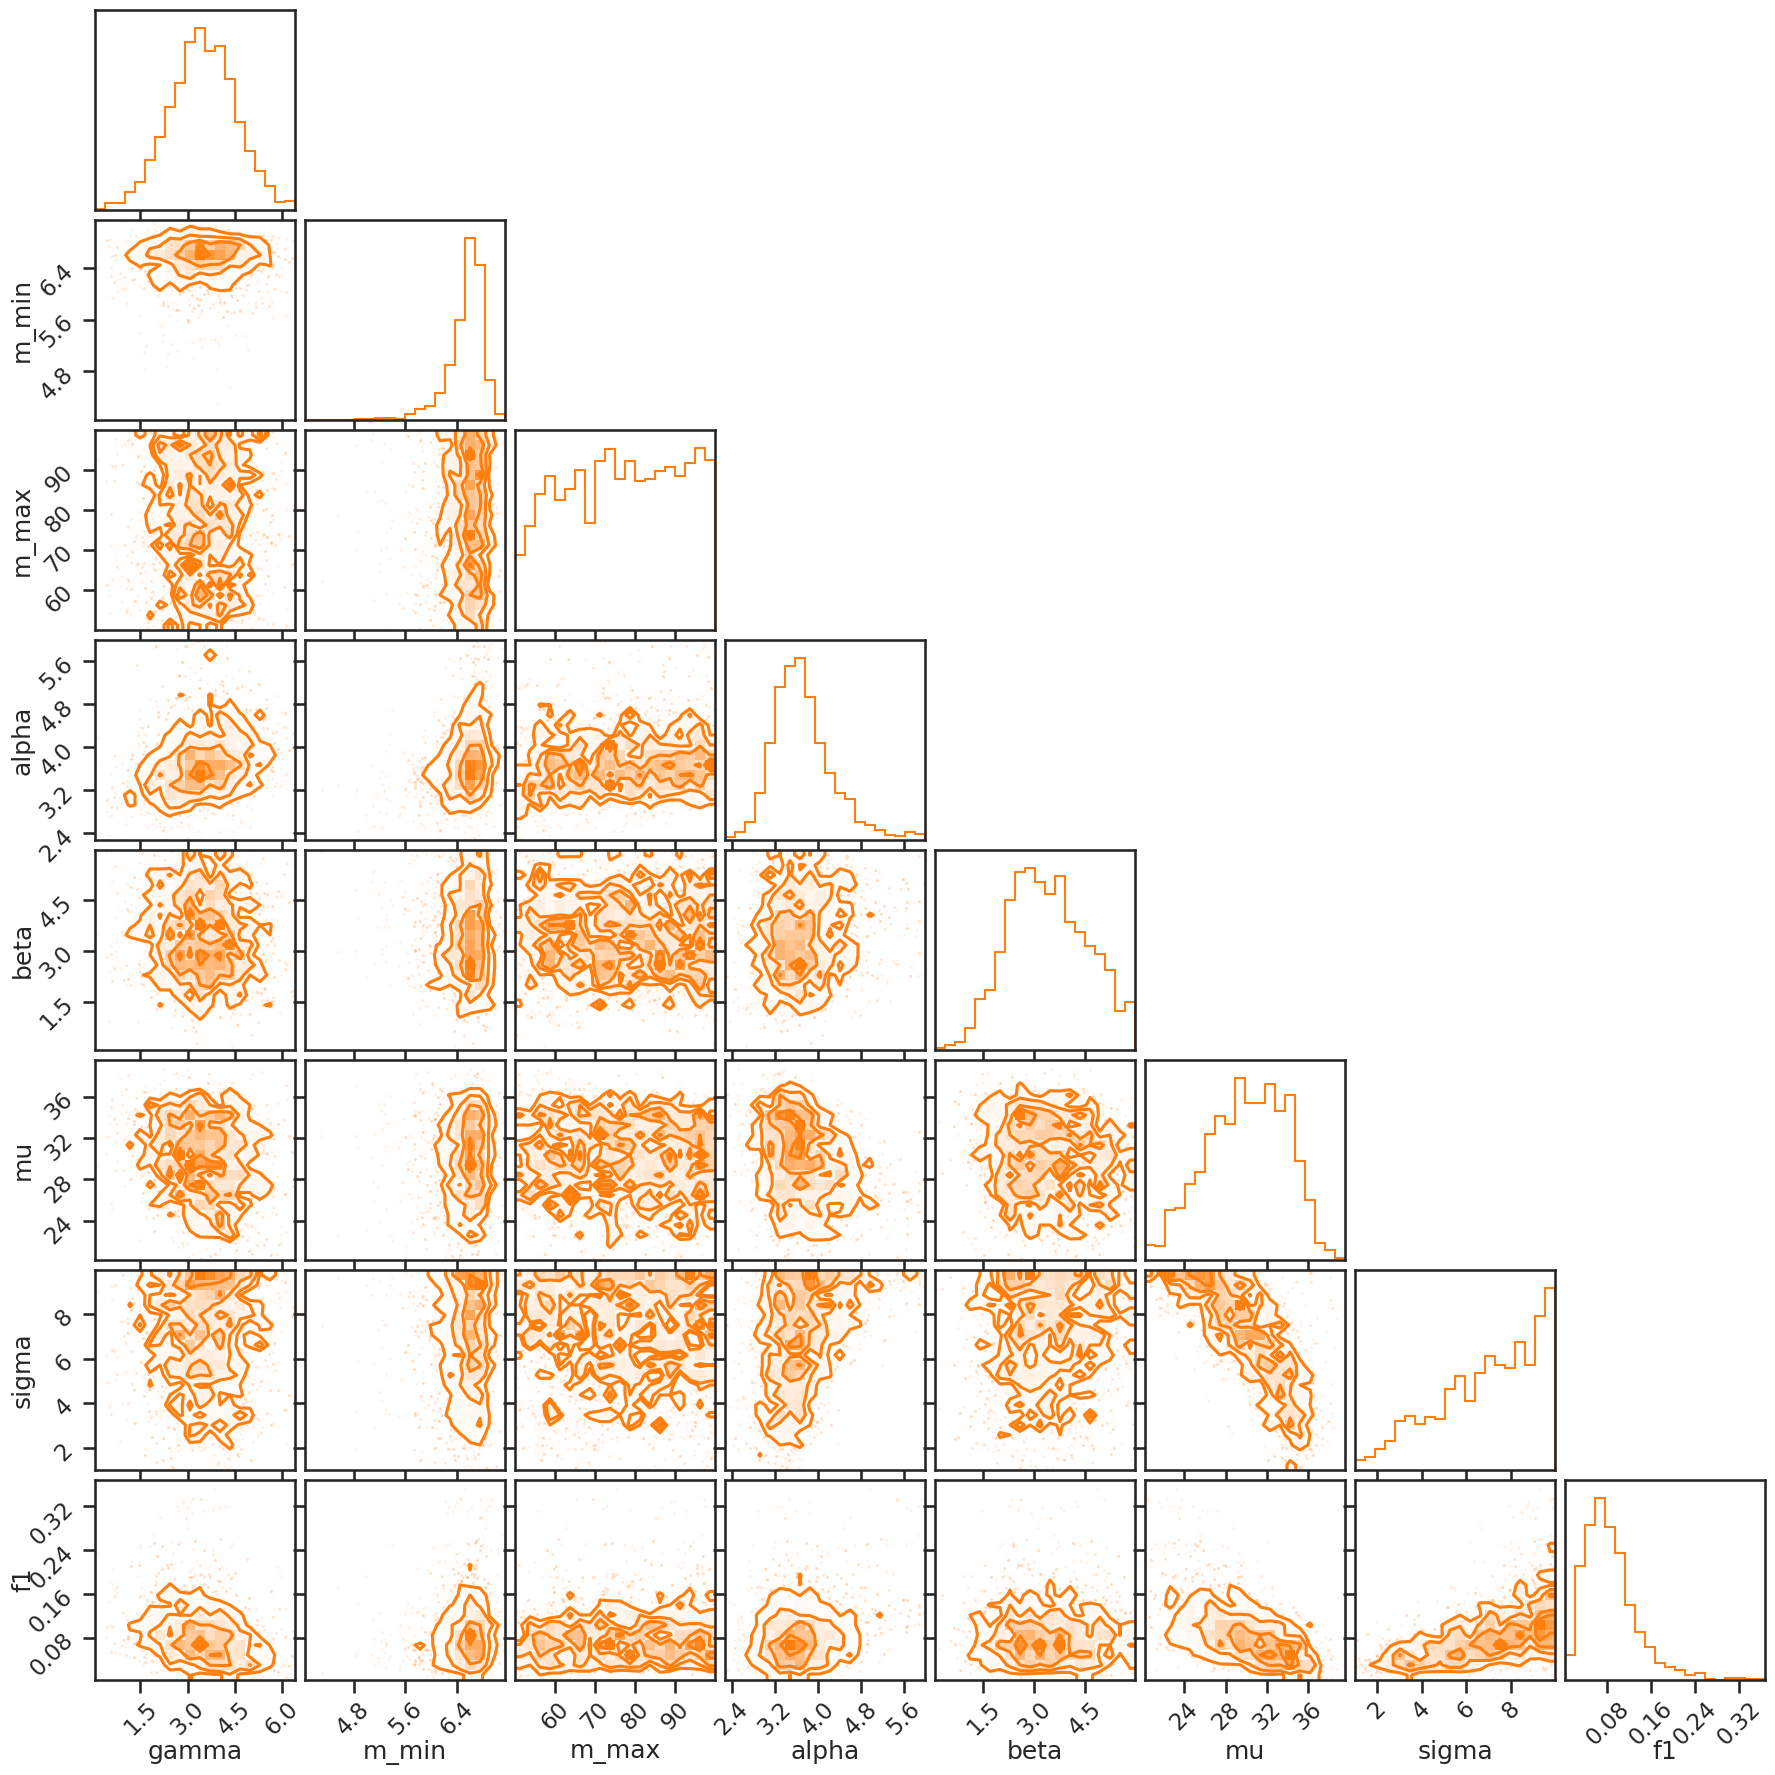

In [43]:
fig3 = corner.corner(post4, labels=param_labels, hist_kwargs={'density': True},
                     color='C1', label='Method 3')

In [ ]:
np.median(post3[:,-1])

np.float64(0.07162858302098357)

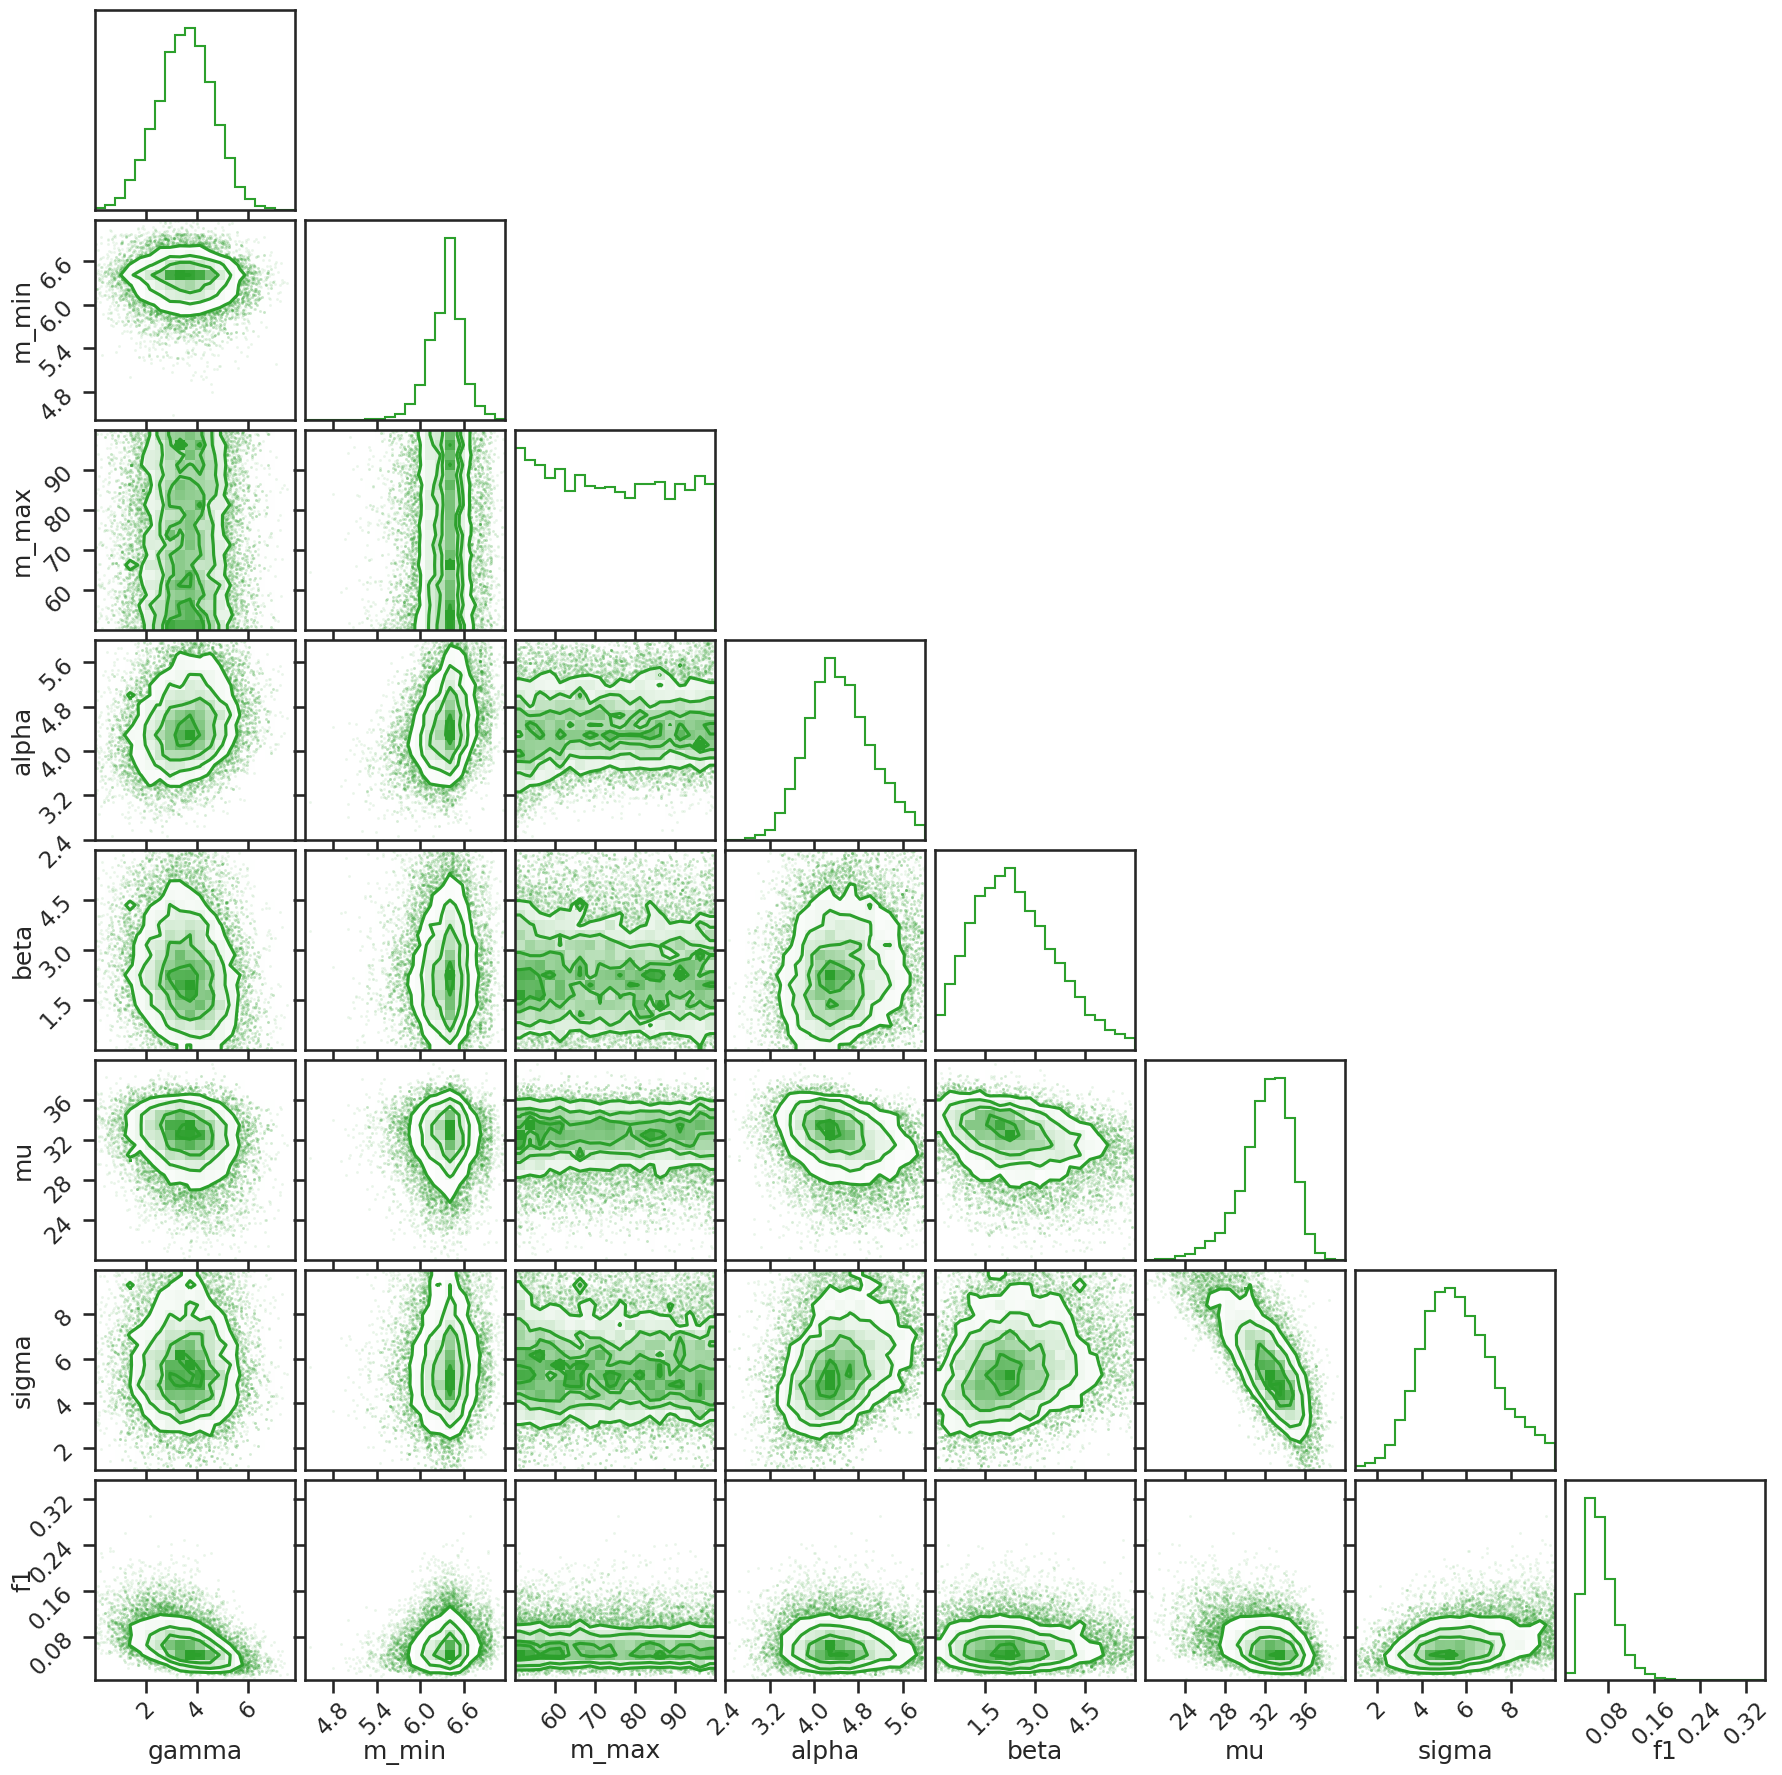

In [46]:
fig3 = corner.corner(post4, labels=param_labels, hist_kwargs={'density': True},
                     color='C2', label='Method 3')

## SECTION 11 – RESULTS & PLOTS


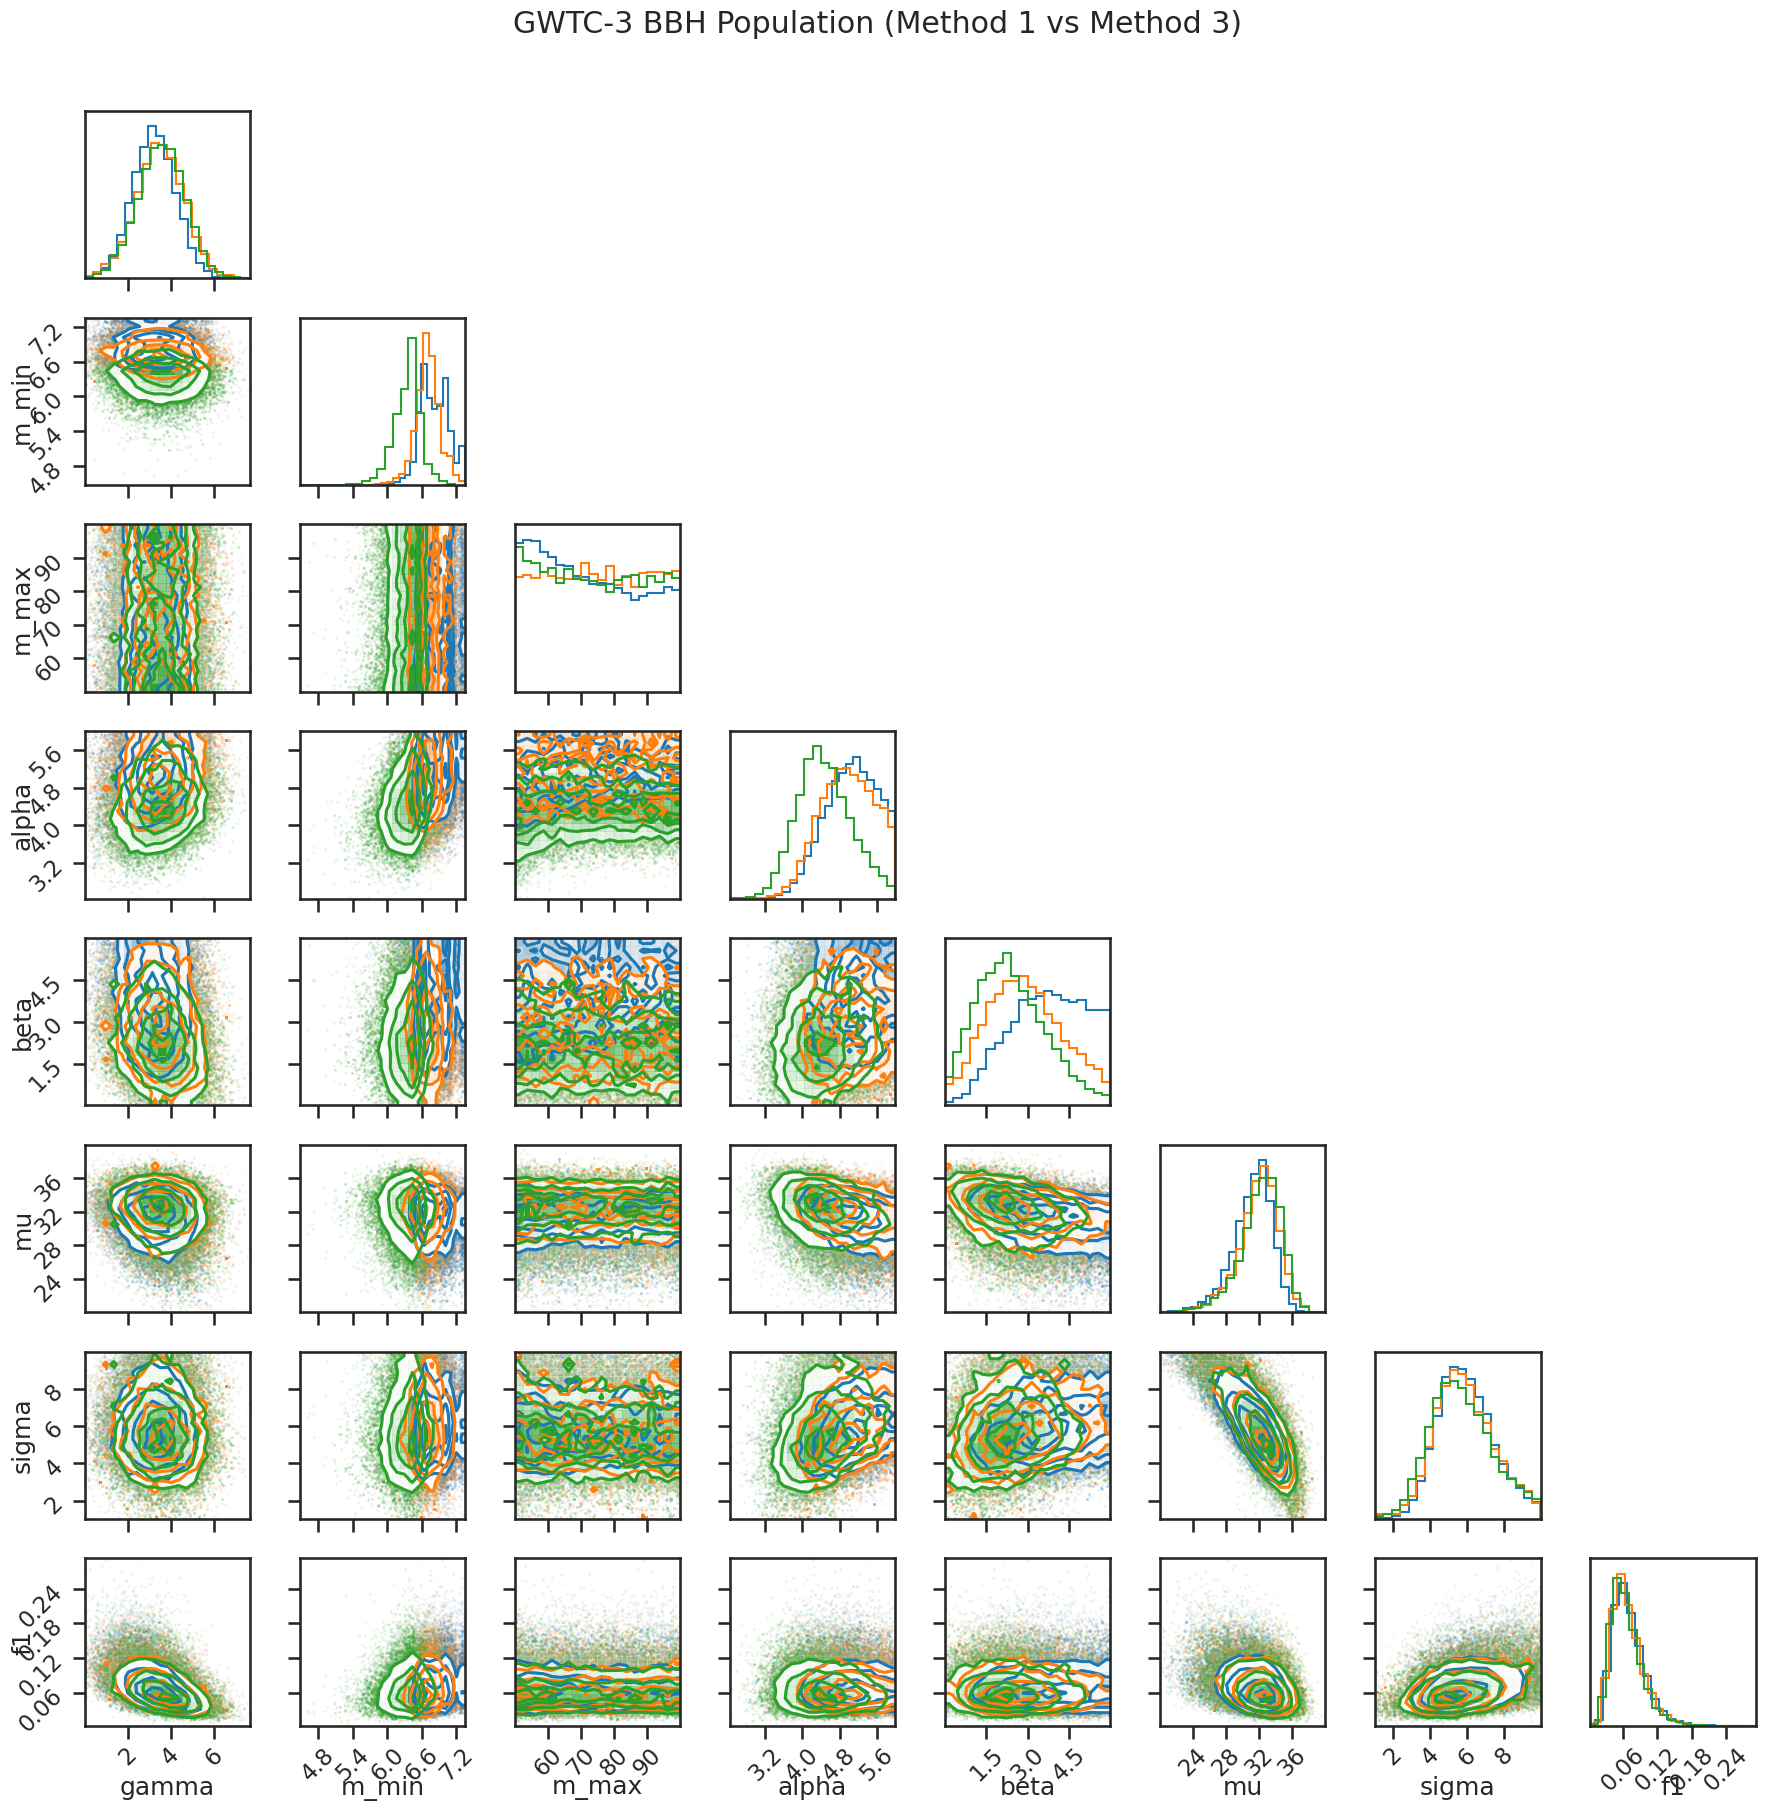

In [ ]:
import corner
# ---- Corner plot ----
fig1 = corner.corner(post1, labels=param_labels, hist_kwargs={'density': True},
                     color='C0', label='Method 1')
fig3 = corner.corner(post3, labels=param_labels, hist_kwargs={'density': True},
                     fig=fig1, color='C1', label='Method 3')
fig4 = corner.corner(post4, labels=param_labels, hist_kwargs={'density': True},
                     fig=fig1, color='C2', label='Method 4')
plt.suptitle('GWTC-3 BBH Population (Method 1 vs Method 3)', y=1.01)
plt.tight_layout()
# plt.savefig('corner_m1_vs_m3.pdf', bbox_inches='tight')
plt.show()

# ---- Save samplers ----
# SAVE_DIR = '/content/drive/MyDrive/popnflow_goog'
# d1sampler.save(f'{SAVE_DIR}/69method1.h5')
# d3sampler.save(f'{SAVE_DIR}/69method3.h5')
# print("Results saved.")

In [ ]:
# ---- Save samplers ----
SAVE_DIR = '/content/drive/MyDrive/popnflow_goog'
d1sampler.save(f'{SAVE_DIR}/69method1.pkl')
# d3sampler.save(f'{SAVE_DIR}/69method3.pkl')
# d4sampler.save(f'{SAVE_DIR}/69method4.pkl')
print("Results saved.")

Results saved.


In [45]:
from dynesty import NestedSampler
from dynesty.utils import resample_equal
# import corner
import pickle

SAVE_DIR = '/content/drive/MyDrive/popnflow_goog'

# 1. Restore the sampler object from your saved .pkl file
d1sampler_loaded = NestedSampler.restore(f'{SAVE_DIR}/69method1.pkl')

# 2. Extract the results object
res1 = d1sampler_loaded.results

# 3. Recalculate weights and get the equal-weighted posterior samples
w1 = np.exp(res1['logwt'] - res1['logz'][-1])
post1 = resample_equal(res1.samples, w1)

print(f"Loaded Method 1: logZ={res1.logz[-1]:.2f} ± {res1.logzerr[-1]:.2f},  "
      f"N_post={post1.shape[0]}")

d3sampler_loaded = NestedSampler.restore(f'{SAVE_DIR}/69method3.pkl')
res3 = d3sampler_loaded.results
w3 = np.exp(res3['logwt'] - res3['logz'][-1])
post3 = resample_equal(res3.samples, w3)

d4sampler_loaded = NestedSampler.restore(f'{SAVE_DIR}/69method4.pkl')
res4 = d4sampler_loaded.results
w4 = np.exp(res4['logwt'] - res4['logz'][-1])
post4 = resample_equal(res4.samples, w4)


Loaded Method 1: logZ=-2124.87 ± 0.08,  N_post=36464


<Figure size 1200x800 with 0 Axes>

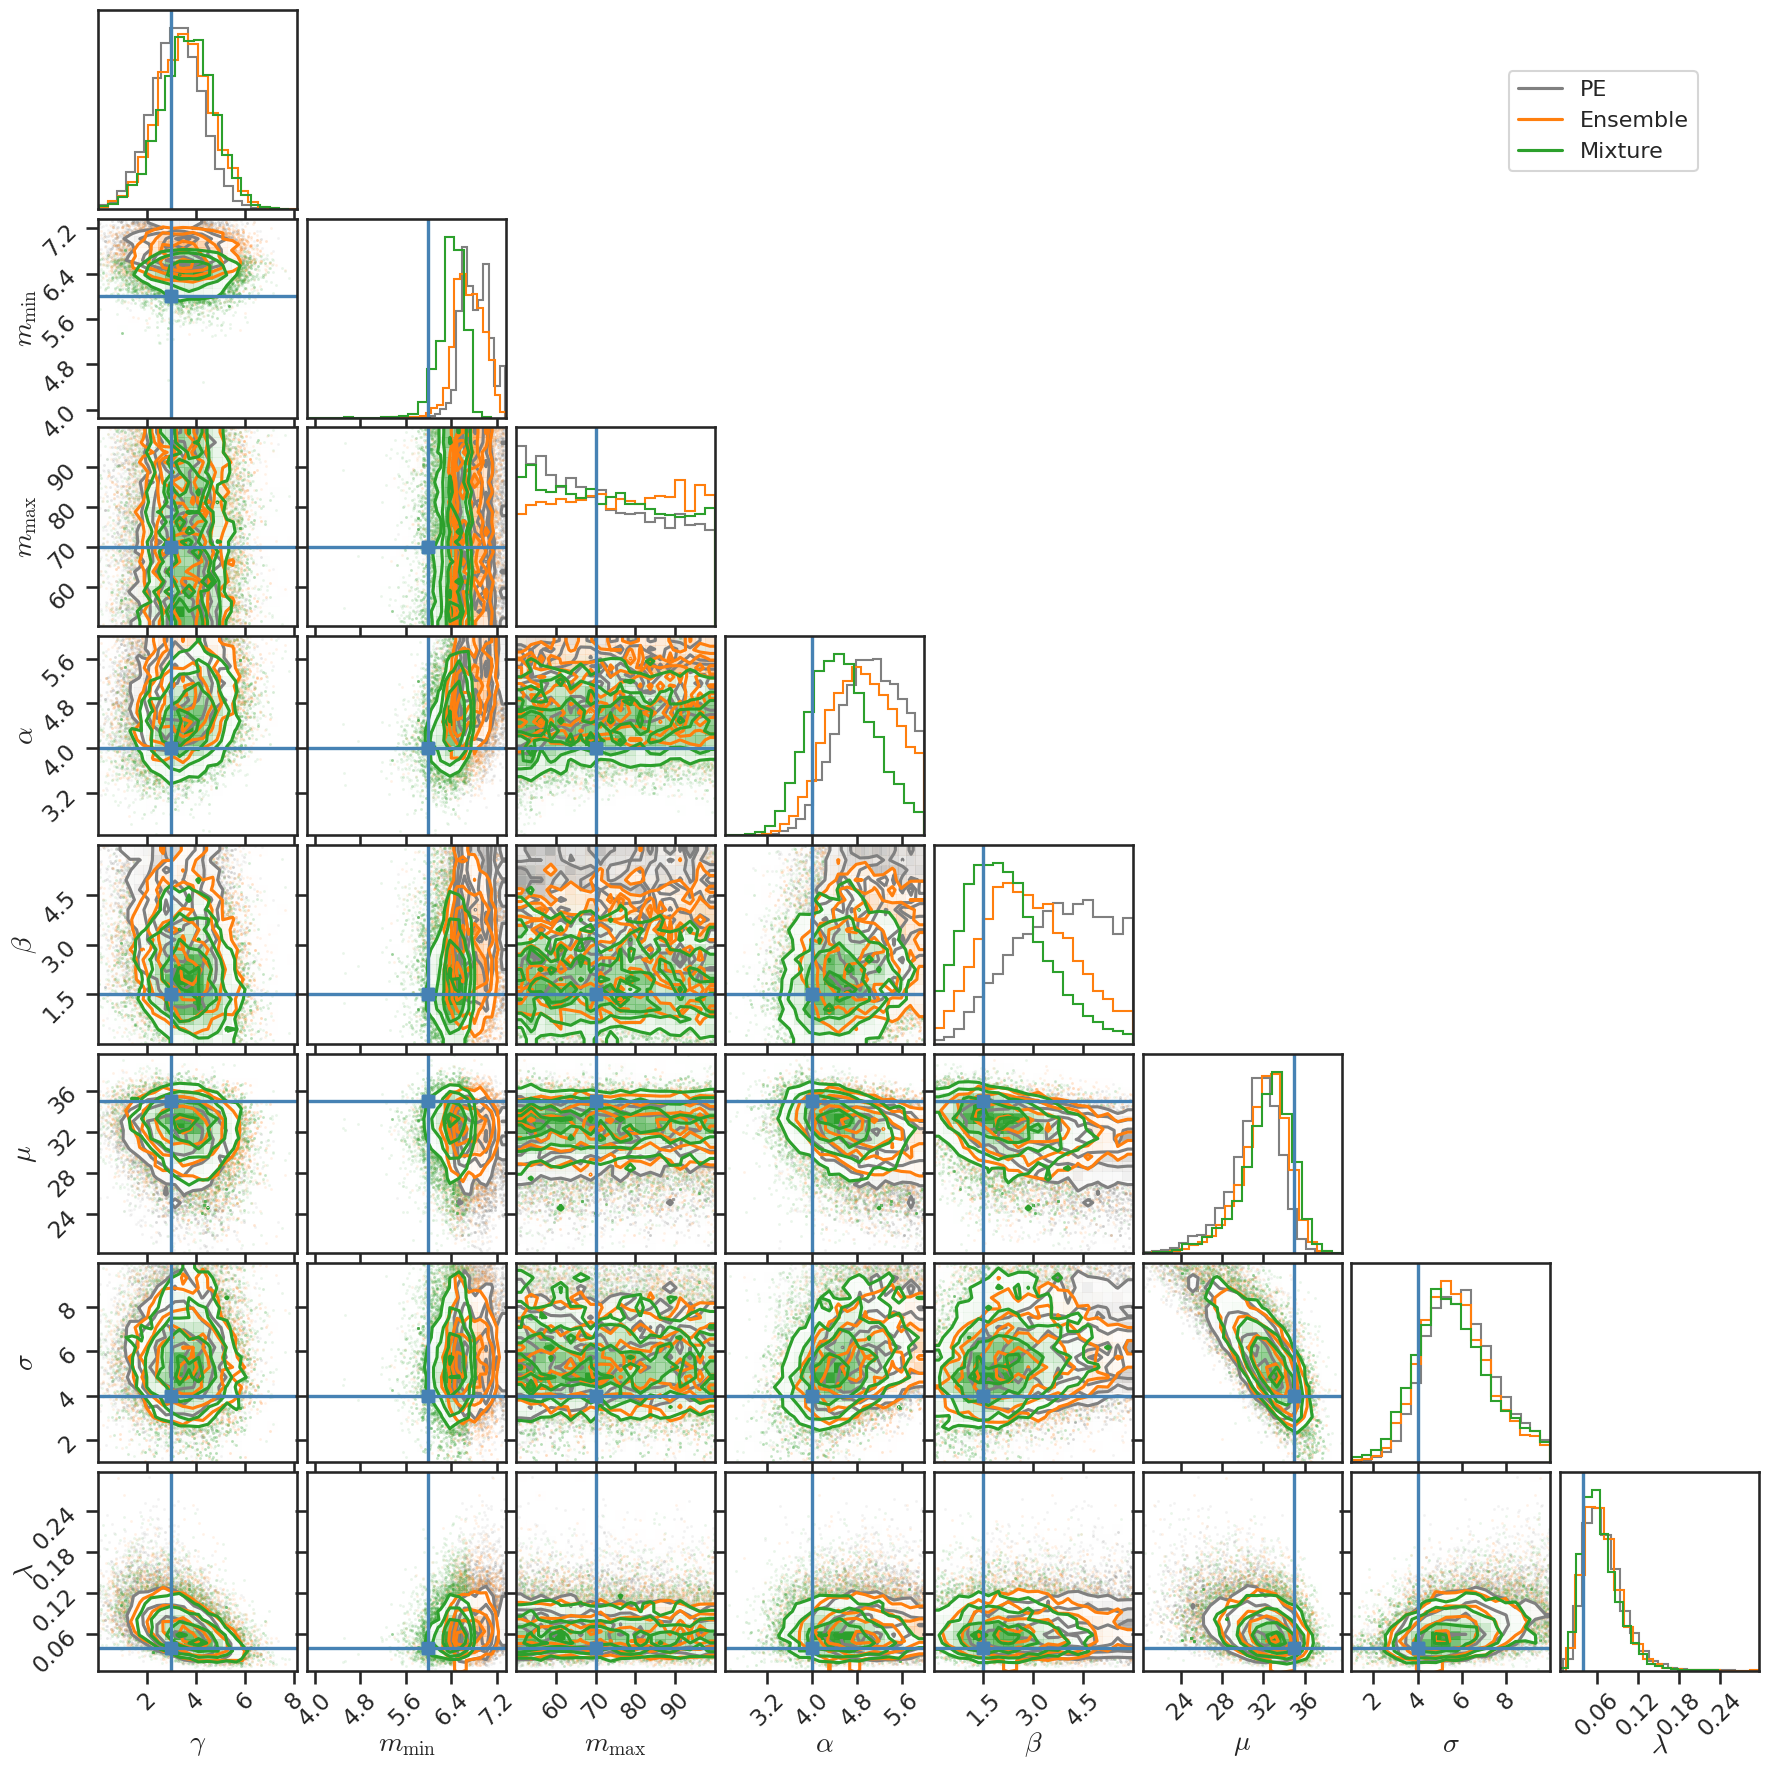

In [ ]:
import corner
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

plt.clf()
truths = [3., 6., 70., 4., 1.5, 35., 4., 0.04]
param_labels_latex = [r'$\gamma$', r'$m_{\min}$', r'$m_{\max}$', r'$\alpha$',
                      r'$\beta$', r'$\mu$', r'$\sigma$', r'$\lambda$']

my_label_kwargs = {"labelpad": 35, "fontsize": 20}
# 1. Create the figure explicitly to control the overall size
fig = plt.figure(figsize=(18, 18))

# 2. Add label_kwargs={'labelpad': 20} to fix the overlap
# 3. Change 'truths_color' to 'truth_color'
fig = corner.corner(post1, fig=fig, labels=param_labels_latex,
                    hist_kwargs={'density': True}, truths=truths,
                    color='grey',
                    label_kwargs=my_label_kwargs,
                    label='PE'
                    )

fig = corner.corner(post3, fig=fig, labels=param_labels_latex,
                    hist_kwargs={'density': True}, truths=truths,
                    color='C1',
                    label='Ensemble'
                    )

fig = corner.corner(post4, fig=fig, labels=param_labels_latex,
                    hist_kwargs={'density': True}, truths=truths,
                    color='C2',
                    label='Mixture'
                    )

# 1. Create dummy lines that match the colors and labels of your corner plots
line1 = mlines.Line2D([], [], color='grey', label='PE')
line2 = mlines.Line2D([], [], color='C1', label='Ensemble')
line3 = mlines.Line2D([], [], color='C2', label='Mixture')

# (Optional) You can also add a line for the truth values
# truth_line = mlines.Line2D([], [], label='Truth')

# 2. Add the legend to the FIGURE, not the plot axes
# 'upper right' places it in that empty triangle space
fig.legend(handles=[line1, line2, line3],
           loc='upper right',
           fontsize=16,
           bbox_to_anchor=(0.95, 0.95)) # You can tweak these numbers to nudge it left/right/up/down

plt.savefig(f'{SAVE_DIR}/corner_m134.pdf', bbox_inches='tight')
plt.show()

# # plt.suptitle('GWTC-3 BBH Population (Method 1 vs Method 3)', y=1.01)

# # Note: corner handles its own grid layout. Sometimes tight_layout()
# # can actually cause squishing in corner plots. If things look weird,
# # try commenting this next line out.
# plt.tight_layout()
# plt.legend()

# plt.show()

In [ ]:
plt.close('all')

In [ ]:
print(pop_mass_args_m4['m_min_1'])